<a href="https://colab.research.google.com/github/Cairo-Henrique/obesity-biostatistics/blob/main/Obesity_Biostat_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div align="center">

# **Análise Bioestatística de Obesidade: Testes de Associação e Regressão Logística**

Investigação estatística de fatores associados à classificação do estado nutricional

<br>

<img src="https://img.shields.io/badge/Python-3670A0?style=for-the-badge&logo=python&logoColor=white">
<img src="https://img.shields.io/badge/Jupyter-F37626?style=for-the-badge&logo=jupyter&logoColor=white">
<img src="https://img.shields.io/badge/Pandas-150458?style=for-the-badge&logo=pandas&logoColor=white">
<img src="https://img.shields.io/badge/SciPy-8CAAE6?style=for-the-badge&logo=scipy&logoColor=white">
<img src="https://img.shields.io/badge/Dataset-Kaggle-20BEFF?style=for-the-badge&logo=kaggle&logoColor=white">

<br><br>

</div>

---

<div align="center">

## Autores

**Grupo G02**  
Disciplina 7600133 — Introdução à Bioestatística

<table>
  <tr>
    <td align="center">
      <strong>Cairo Henrique Vaz Cotrim</strong>
    </td>
    <td align="center">
      <strong>Uebton Oliveira da Silva</strong>
    </td>
  </tr>
</table>

Universidade de São Paulo — USP

</div>

---

## Resumo

Neste projeto, desenvolvemos uma análise bioestatística completa do [Obesity Dataset](https://www.kaggle.com/datasets/suleymansulak/obesity-dataset), com 1.610 observações, integrando **análise exploratória, visualização de dados, testes de hipóteses, medidas de associação e modelagem estatística em Python**. Investigamos relações entre características demográficas, hábitos e classificação do estado nutricional, utilizando testes qui-quadrado, V de Cramér, correlações, Kruskal-Wallis, comparações post-hoc de Dunn e regressões logísticas ordinal e multinomial. Identificamos associações de grande magnitude entre idade e classificação nutricional ($\varepsilon_R^2 = 0{,}4244$), além de associações relevantes com número de refeições, consumo de vegetais e fast food. A hipótese de chances proporcionais da regressão ordinal foi rejeitada, motivando a adoção de um modelo multinomial, que apresentou significância global ($p < 0{,}001$) e permitiu avaliar os efeitos relativos de idade, sexo, histórico familiar e consumo de fast food.

---

## Fonte dos dados

| Campo | Informação |
|:---|:---|
| **Conjunto de dados** | Obesity Dataset |
| **Autor** | Suleyman Sulak |
| **Plataforma** | Kaggle |
| **Observações** | 1.610 indivíduos |
| **Variável de interesse** | Classificação do estado nutricional |
| **Acesso** | [Obesity Dataset — Kaggle](https://www.kaggle.com/datasets/suleymansulak/obesity-dataset/data) |

---

## Organização do notebook

O desenvolvimento está dividido nas seguintes etapas:

1. **Importação e preparação dos dados:** carregamento, organização e tratamento das variáveis.
2. **Análise descritiva e exploratória:** caracterização da amostra, distribuições, visualizações e identificação de possíveis outliers.
3. **Análise de associações:** aplicação de testes qui-quadrado, cálculo do V de Cramér e análise de correlações.
4. **Comparação entre grupos:** avaliação dos pressupostos estatísticos e aplicação dos testes de Kruskal-Wallis e Dunn.
5. **Modelagem estatística:** avaliação da regressão logística ordinal e aplicação da regressão logística multinomial.
6. **Considerações finais:** síntese dos resultados, interpretação dos achados e discussão das limitações.

---

In [ ]:
# @title
from IPython.display import HTML, display
import html

membros = [
    {
        "nome": "Cairo Henrique Vaz Cotrim",
        "iniciais": "C",
        "linkedin": "https://www.linkedin.com/in/cairo-cotrim-75a986340/"
    },
    {
        "nome": "Uebton Oliveira da Silva",
        "iniciais": "U",
        "linkedin": "https://www.linkedin.com/in/uebton-oliveira-da-silva-0567a1242/"
    },
]

cards_html = ""

for membro in membros:
    nome = html.escape(membro["nome"])
    iniciais = html.escape(membro["iniciais"])
    linkedin = html.escape(membro["linkedin"], quote=True)

    cards_html += f"""
    <div class="member-card">
        <div class="avatar">{iniciais}</div>

        <div class="member-name">{nome}</div>

        <div class="member-role">Integrante</div>

        <a class="linkedin-link"
           href="{linkedin}"
           target="_blank"
           rel="noopener noreferrer">
            <svg width="16" height="16" viewBox="0 0 24 24"
                 fill="currentColor" style="vertical-align:middle;">
                <path d="M20.447 20.452h-3.554v-5.569
                c0-1.328-.027-3.037-1.852-3.037
                -1.853 0-2.136 1.445-2.136 2.939v5.667
                H9.35V9h3.414v1.561h.049
                c.476-.9 1.637-1.85 3.369-1.85
                3.601 0 4.267 2.37 4.267 5.455v6.286z
                M5.337 7.433a2.062 2.062 0 1 1
                0-4.124 2.062 2.062 0 0 1 0 4.124z
                M7.119 20.452H3.555V9h3.564v11.452z
                M22.225 0H1.771C.792 0 0 .774 0
                1.729v20.542C0 23.227.792 24
                1.771 24h20.451C23.2 24 24
                23.227 24 22.271V1.729C24
                .774 23.2 0 22.222 0h.003z"/>
            </svg>
            <span>LinkedIn</span>
            <span class="arrow">↗</span>
        </a>
    </div>
    """

html_final = f"""
<style>
    .members-container {{
        display: flex;
        justify-content: center;
        align-items: stretch;
        flex-wrap: wrap;
        gap: 28px;
        padding: 35px 15px;
        font-family: 'Inter', 'Segoe UI', sans-serif;
    }}

    .member-card {{
        width: 230px;
        padding: 28px 22px 24px;
        box-sizing: border-box;
        text-align: center;
        background: linear-gradient(145deg, #ffffff, #f7f9fc);
        border: 1px solid #e8edf4;
        border-radius: 18px;
        box-shadow: 0 5px 20px rgba(27, 45, 75, 0.07);
        transition: transform 0.25s ease, box-shadow 0.25s ease;
    }}

    .member-card:hover {{
        transform: translateY(-6px);
        box-shadow: 0 12px 28px rgba(27, 45, 75, 0.13);
    }}

    .avatar {{
        width: 86px;
        height: 86px;
        margin: 0 auto 19px;
        display: flex;
        justify-content: center;
        align-items: center;
        border-radius: 50%;
        background: linear-gradient(135deg, #0A66C2, #478FE0);
        color: white;
        font-size: 27px;
        font-weight: 700;
        letter-spacing: 1px;
        box-shadow: 0 5px 14px rgba(10, 102, 194, 0.22);
    }}

    .member-name {{
        min-height: 44px;
        display: flex;
        justify-content: center;
        align-items: center;
        color: #243247;
        font-size: 15px;
        font-weight: 650;
        line-height: 1.45;
    }}

    .member-role {{
        margin-top: 7px;
        color: #8491a3;
        font-size: 12px;
        letter-spacing: 0.7px;
        text-transform: uppercase;
    }}

    .linkedin-link {{
        display: inline-flex;
        align-items: center;
        justify-content: center;
        gap: 7px;
        margin-top: 22px;
        padding: 9px 17px;
        border: 1px solid #d9e8f8;
        border-radius: 8px;
        background: #eff6fd;
        color: #0A66C2;
        font-size: 13px;
        font-weight: 600;
        text-decoration: none;
        transition: background 0.2s ease, color 0.2s ease;
    }}

    .linkedin-link:hover {{
        background: #0A66C2;
        color: white;
    }}

    .arrow {{
        font-size: 14px;
    }}
</style>

<div class="members-container">
    {cards_html}
</div>
"""

display(HTML(html_final))

## **Explicação do dataset**

---

| Attributes | Values |
|---|---|
| Sex | 1. Male (712)<br>2. Female (898) |
| Age | Values in integers |
| Height | Values in integers (cm) |
| Overweight/Obese Families | 1. Yes (266)<br>2. No (1344) |
| Consumption of Fast Food | 1. Yes (436)<br>2. No (1174) |
| Frequency of Consuming Vegetables | 1. Rarely (400)<br>2. Sometimes (708)<br>3. Always (502) |
| Number of Main Meals Daily | 1. 1-2 (444)<br>2. 3 (928)<br>3. 3+ (238) |
| Food Intake Between Meals | 1. Rarely (346)<br>2. Sometimes (564)<br>3. Usually (417)<br>4. Always (283) |
| Smoking | 1. Yes (492)<br>2. No (1118) |
| Liquid Intake Daily | 1. amount smaller than one liter (456)<br>2. Within the range of 1 to 2 liters (523)<br>3. In excess of 2 liters (631) |
| Calculation Of Calorie Intake | 1. Yes (286)<br>2. No (1324) |
| Physical Exercise | 1. No physical activity (206)<br>2. In the range of 1-2 days (290)<br>3. In the range of 3-4 days (370)<br>4. In the range of 5-6 days (358)<br>5. 6+ days (386) |
| Schedule Dedicated to Technology | 1. Between 0 and 2 hours (382)<br>2. Between 3 and 5 hours (826)<br>3. Exceeding five hours (402) |
| Type of Transportation Used | 1. Automobile (660)<br>2. Motorbike (94)<br>3. Bike (116)<br>4. Public transportation (602)<br>5. Walking (138) |
| Class | 1. Underweight (73)<br>2. Normal (658)<br>3. Overweight (592)<br>4. Obesity (287) |

## **Bibliotecas**

In [1]:
!pip install scikit-posthocs

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import scikit_posthocs as sp
from itertools import combinations
import warnings

import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from statsmodels.miscmodels.ordinal_model import OrderedModel
from statsmodels.stats.outliers_influence import variance_inflation_factor

from scipy.io import arff
from scipy.stats import chi2_contingency
from scipy.stats import norm
from scipy.stats import pearsonr, spearmanr
from scipy.stats import shapiro, levene, probplot
from scipy.stats import kruskal
from scipy.stats import chi2 as chi2_dist # para evitar conflito com a variável 'chi2'

## **Valor de significância estatística do projeto**

In [3]:
# Significância estatística padronizada para todas as seções deste notebook
alpha = 0.05

## **Download dos dados**

In [4]:
!gdown 1fDLax28j9F6Un81IpxHoHXHz8CdsmGQk

Downloading...
From: https://drive.google.com/uc?id=1fDLax28j9F6Un81IpxHoHXHz8CdsmGQk
To: /content/Obesity_Dataset.arff
100% 54.0k/54.0k [00:00<00:00, 54.5MB/s]


In [5]:
data, meta  = arff.loadarff(r'Obesity_Dataset.arff')
df = pd.DataFrame(data)

In [6]:
# Padronização dos valores da coluna "Class" em strings mais informativas
mapeamento = {
    b'1': 'Underweight',
    b'2': 'Normal',
    b'3': 'Overweight',
    b'4': 'Obesity'
}

df['Class'] = df['Class'].map(mapeamento)

ordem = [
    'Underweight',
    'Normal',
    'Overweight',
    'Obesity'
]

df['Class'] = pd.Categorical(
    df['Class'],
    categories=ordem,
    ordered=True
)

In [7]:
df.head(10)

,Sex,Age,Height,Overweight_Obese_Family,Consumption_of_Fast_Food,Frequency_of_Consuming_Vegetables,Number_of_Main_Meals_Daily,Food_Intake_Between_Meals,Smoking,Liquid_Intake_Daily,Calculation_of_Calorie_Intake,Physical_Excercise,Schedule_Dedicated_to_Technology,Type_of_Transportation_Used,Class
0,2.0,18.0,155.0,2.0,2.0,3.0,1.0,3.0,2.0,1.0,2.0,3.0,3.0,4.0,Normal
1,2.0,18.0,158.0,2.0,2.0,3.0,1.0,1.0,2.0,1.0,2.0,1.0,3.0,3.0,Normal
2,2.0,18.0,159.0,2.0,2.0,2.0,1.0,3.0,2.0,3.0,2.0,2.0,3.0,4.0,Normal
3,2.0,18.0,162.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,3.0,4.0,Normal
4,2.0,18.0,165.0,2.0,1.0,2.0,1.0,3.0,2.0,1.0,2.0,3.0,3.0,2.0,Normal
5,2.0,18.0,176.0,1.0,1.0,1.0,1.0,4.0,2.0,2.0,2.0,4.0,3.0,4.0,Normal
6,2.0,19.0,152.0,2.0,2.0,3.0,1.0,1.0,2.0,3.0,2.0,2.0,3.0,2.0,Normal
7,2.0,19.0,158.0,2.0,2.0,3.0,2.0,4.0,2.0,1.0,1.0,1.0,3.0,3.0,Normal
8,2.0,19.0,159.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,2.0,2.0,3.0,4.0,Normal
9,2.0,19.0,162.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,2.0,3.0,4.0,Overweight


## **Análise descritiva e exploratória**

In [8]:
resultado = pd.DataFrame({
    'Valores únicos': df.nunique(),
    'Valores ausentes': df.isna().sum(),
    'Total de valores': df.count()
})

print(resultado.sort_values('Valores únicos'))

                                   Valores únicos  Valores ausentes  \
Sex                                             2                 0   
Overweight_Obese_Family                         2                 0   
Consumption_of_Fast_Food                        2                 0   
Smoking                                         2                 0   
Calculation_of_Calorie_Intake                   2                 0   
Liquid_Intake_Daily                             3                 0   
Number_of_Main_Meals_Daily                      3                 0   
Frequency_of_Consuming_Vegetables               3                 0   
Schedule_Dedicated_to_Technology                3                 0   
Class                                           4                 0   
Food_Intake_Between_Meals                       4                 0   
Physical_Excercise                              5                 0   
Type_of_Transportation_Used                     5                 0   
Age   

- 'Age' e 'Height' são as únicas variáveis numéricas. Todas as outras são categóricas.

In [9]:
# Estatística descritiva das variáveis categóricas

colunas_cat = [
    c for c in df.columns
    if c not in ['Age', 'Height']
]

for coluna in colunas_cat:

    print('\n', '=' * 60)
    print(coluna.upper())
    print('=' * 60)

    frequencias = df[coluna].value_counts().sort_index()

    tabela = pd.DataFrame({
        'Frequência': frequencias,
        'Porcentagem (%)': (
            frequencias / len(df) * 100
        ).round(2)
    })

    print(tabela)


SEX
     Frequência  Porcentagem (%)
Sex                             
1.0         712            44.22
2.0         898            55.78

OVERWEIGHT_OBESE_FAMILY
                         Frequência  Porcentagem (%)
Overweight_Obese_Family                             
1.0                             266            16.52
2.0                            1344            83.48

CONSUMPTION_OF_FAST_FOOD
                          Frequência  Porcentagem (%)
Consumption_of_Fast_Food                             
1.0                              436            27.08
2.0                             1174            72.92

FREQUENCY_OF_CONSUMING_VEGETABLES
                                   Frequência  Porcentagem (%)
Frequency_of_Consuming_Vegetables                             
1.0                                       400            24.84
2.0                                       708            43.98
3.0                                       502            31.18

NUMBER_OF_MAIN_MEALS_DAILY
      

In [10]:
# Estatística descritiva das variáveis quantitativas
print(df[['Age', 'Height']].describe())

               Age       Height
count  1610.000000  1610.000000
mean     33.115528   167.741615
std       9.835076     7.979873
min      18.000000   150.000000
25%      25.000000   161.000000
50%      32.000000   168.000000
75%      41.000000   174.000000
max      54.000000   193.000000


- Nota-se que a idade dos indivíduos está no intervalo [18,54]. Portanto, não há menores de idade e nem idosos no dataset deste projeto.

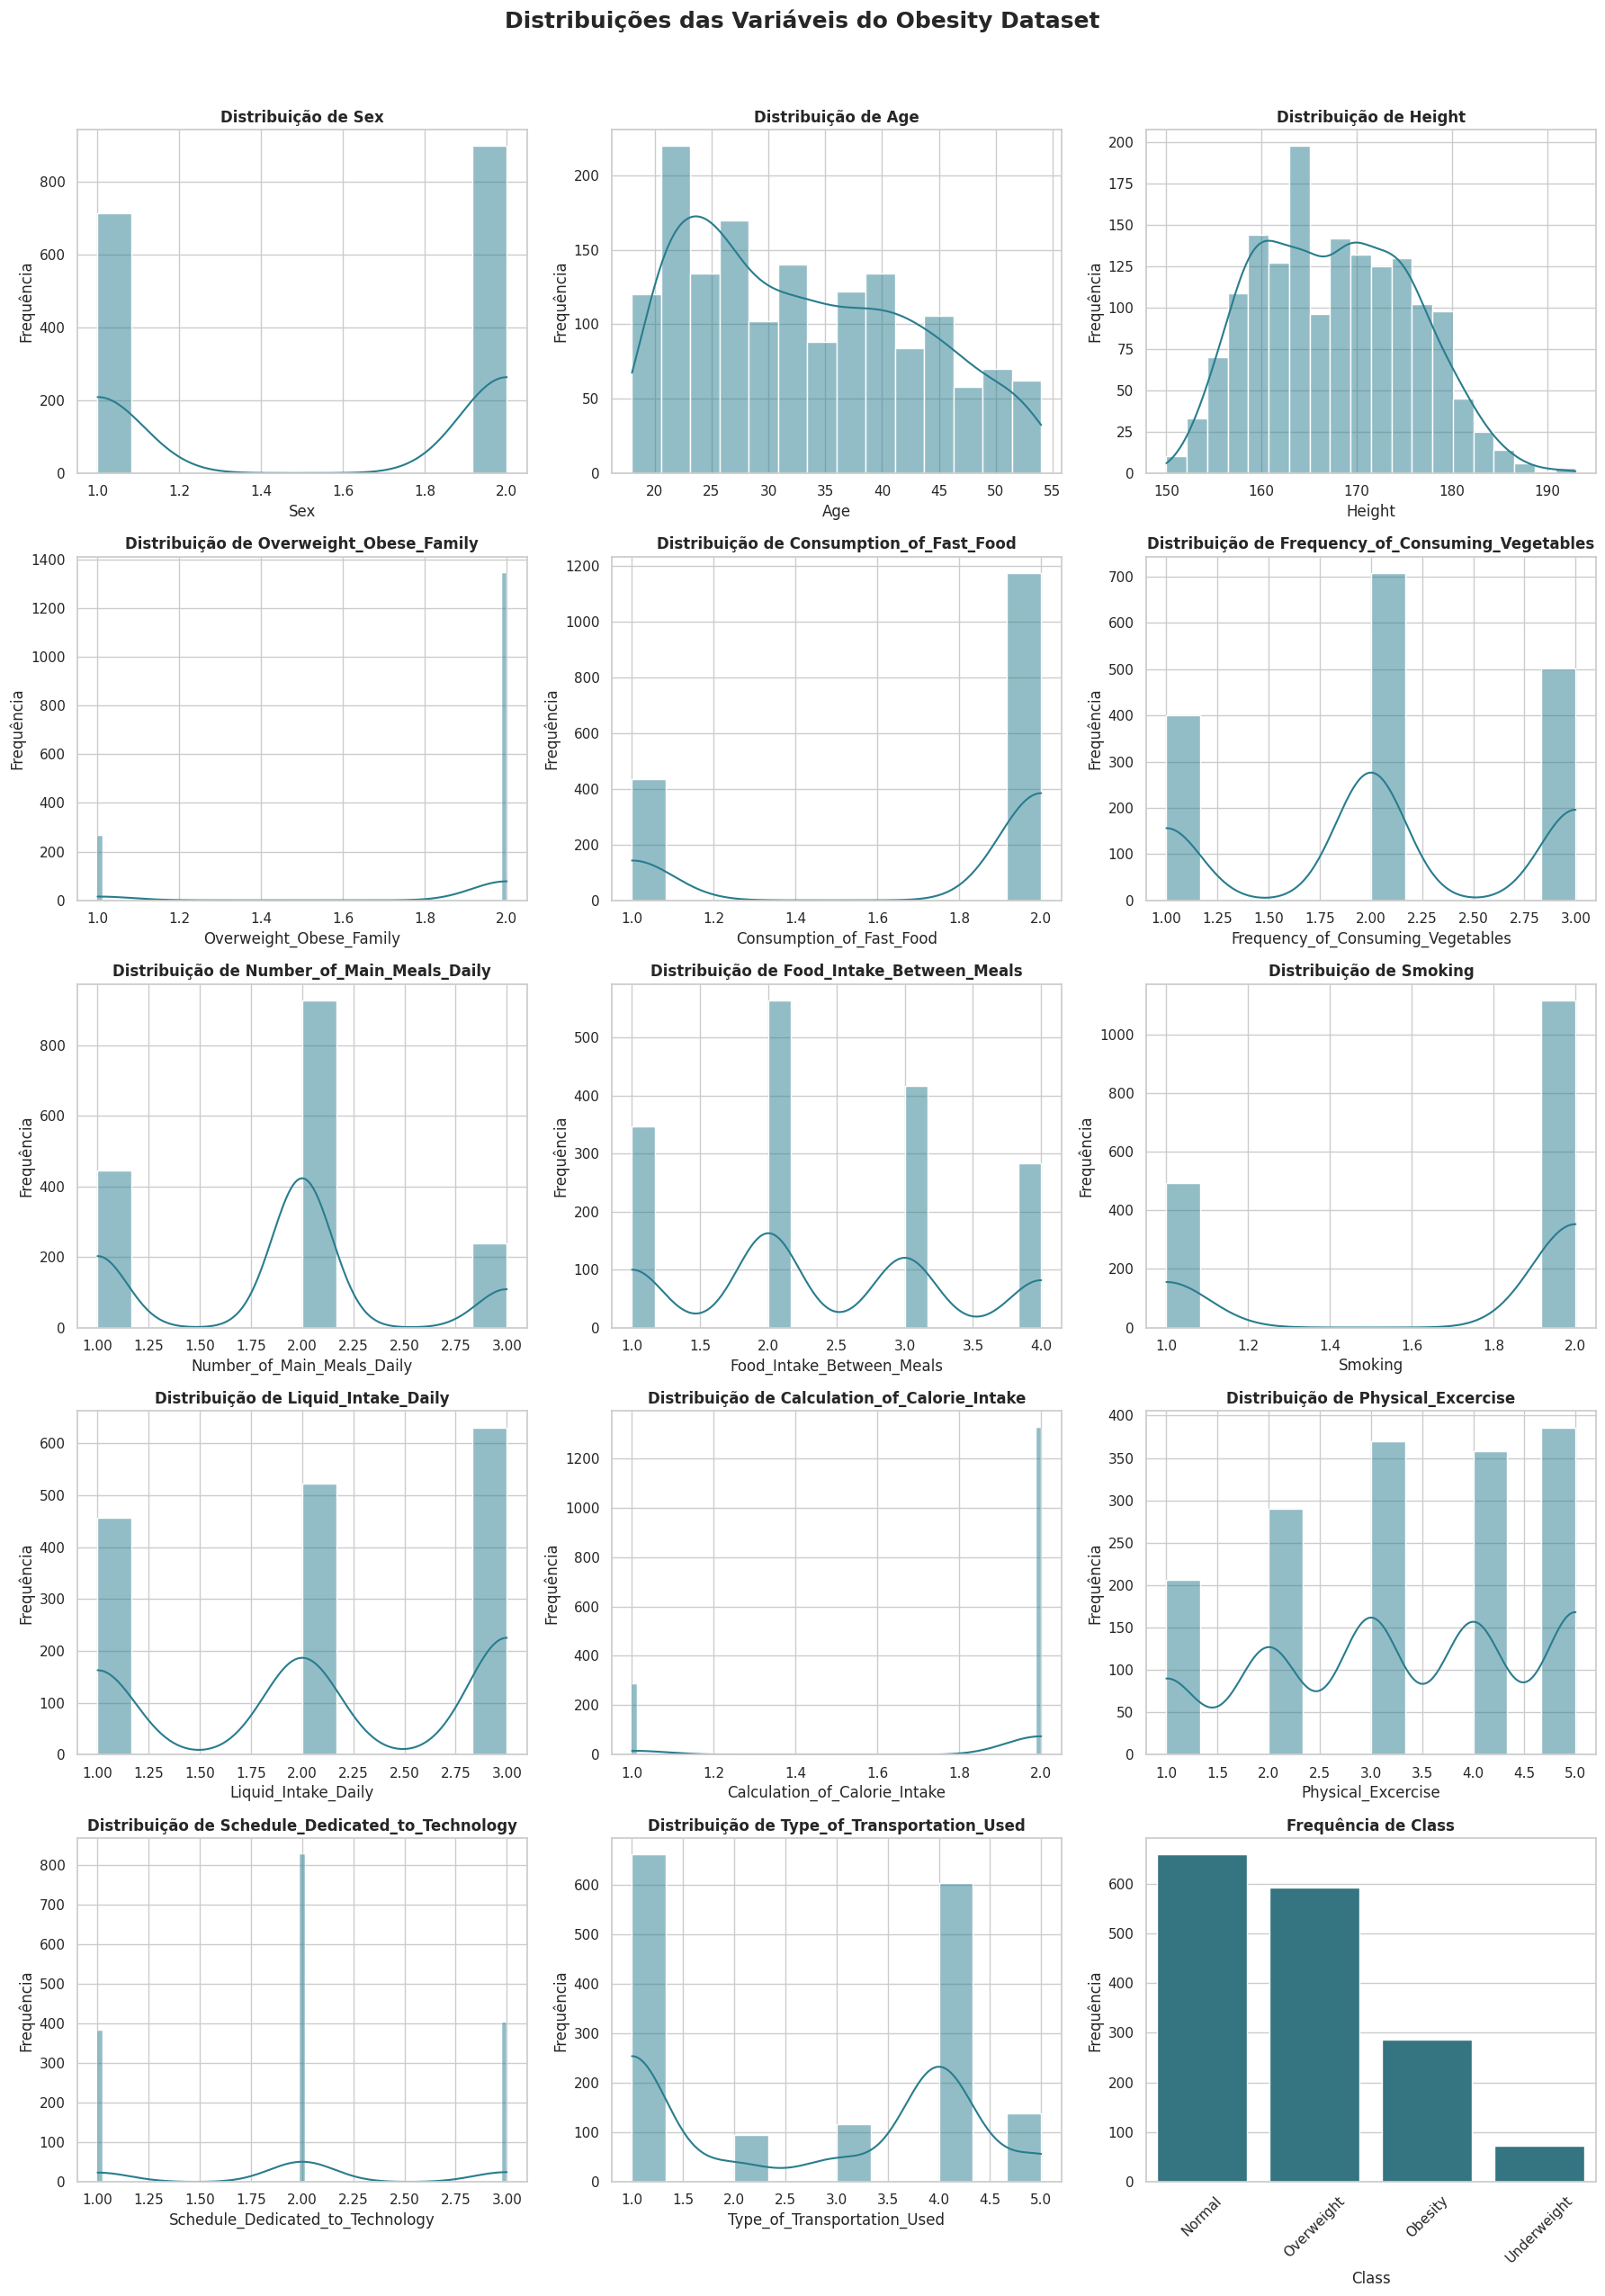

In [12]:
######################################
# HISTOGRAMAS E GRÁFICOS DE BARRAS
######################################

# Configuração visual
sns.set_theme(style="whitegrid", palette="viridis")

# Identificação dos tipos de variáveis
num_cols = df.select_dtypes(include="number").columns.tolist()
cat_cols = df.select_dtypes(exclude="number").columns.tolist()

# Número de gráficos por linha
n_cols = 3
n_plots = len(num_cols) + len(cat_cols)
n_rows = int(n_plots / n_cols)

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(18, 5 * n_rows)
)

axes = axes.flatten()

# Histogramas das variáveis numéricas
plot_idx = 0

for col in num_cols:
    sns.histplot(
        data=df,
        x=col,
        kde=True,
        ax=axes[plot_idx],
        color="#287D8E"
    )

    axes[plot_idx].set_title(
        f"Distribuição de {col}",
        fontsize=12,
        fontweight="bold"
    )
    axes[plot_idx].set_xlabel(col)
    axes[plot_idx].set_ylabel("Frequência")
    plot_idx += 1

# Gráficos de frequência das variáveis categóricas
for col in cat_cols:
    order = df[col].value_counts().index

    sns.countplot(
        data=df,
        x=col,
        order=order,
        ax=axes[plot_idx],
        color="#287D8E"
    )

    axes[plot_idx].set_title(
        f"Frequência de {col}",
        fontsize=12,
        fontweight="bold"
    )
    axes[plot_idx].set_xlabel(col)
    axes[plot_idx].set_ylabel("Frequência")
    axes[plot_idx].tick_params(axis="x", rotation=45)
    plot_idx += 1

# Remover eixos vazios
for idx in range(plot_idx, len(axes)):
    fig.delaxes(axes[idx])

plt.suptitle(
    "Distribuições das Variáveis do Obesity Dataset",
    fontsize=18,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()
plt.show()

        Outliers  Total válido  Porcentagem (%)
Age            0          1610              0.0
Height         0          1610              0.0


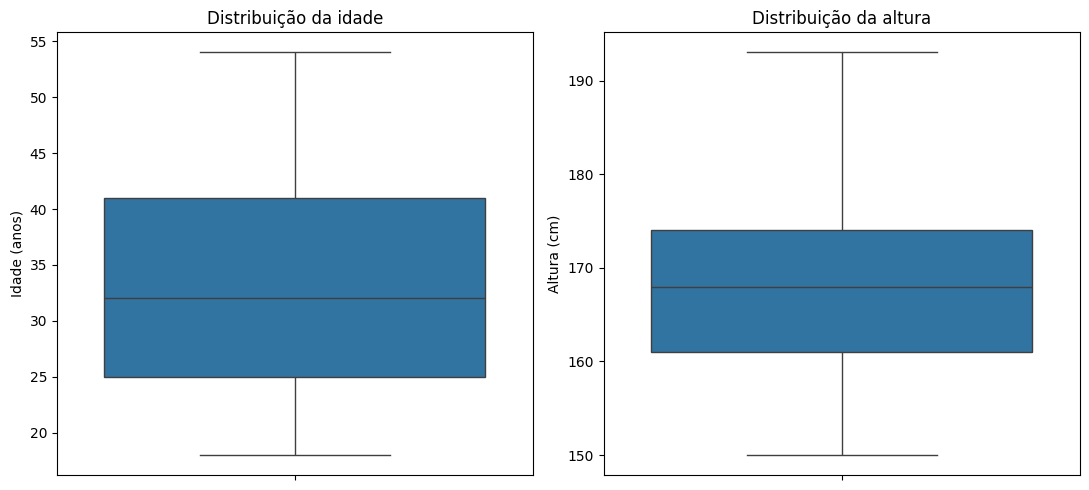

In [ ]:
######################################
# BOXPLOTS DAS VARIÁVEIS QUANTITATIVAS
######################################

# Apenas variáveis quantitativas
df_num = df[['Age', 'Height']]

Q1 = df_num.quantile(0.25)
Q3 = df_num.quantile(0.75)
IQR = Q3 - Q1

limite_inf = Q1 - 1.5 * IQR
limite_sup = Q3 + 1.5 * IQR

outliers = (
    df_num.lt(limite_inf) |
    df_num.gt(limite_sup)
)

resultado = pd.DataFrame({
    'Outliers': outliers.sum(),
    'Total válido': df_num.count(),
    'Porcentagem (%)': (
        outliers.sum() / df_num.count() * 100
    ).round(2)
})

print(resultado)

# Plota os boxplots
fig, axes = plt.subplots(1, 2, figsize=(11, 5))

sns.boxplot(y=df['Age'], ax=axes[0])
axes[0].set_title('Distribuição da idade')
axes[0].set_ylabel('Idade (anos)')

sns.boxplot(y=df['Height'], ax=axes[1])
axes[1].set_title('Distribuição da altura')
axes[1].set_ylabel('Altura (cm)')

plt.tight_layout()
plt.show()

- Pelo critério de outliers usual, não existem outliers de idade e altura no dataset.
- Os boxplots mostram que, à primeira vista, as alturas estão bem variadas.
- Já as idades parecem se concentrar mais nos valores entre 25 e 40 anos, além do intervalo de idade já comentado.

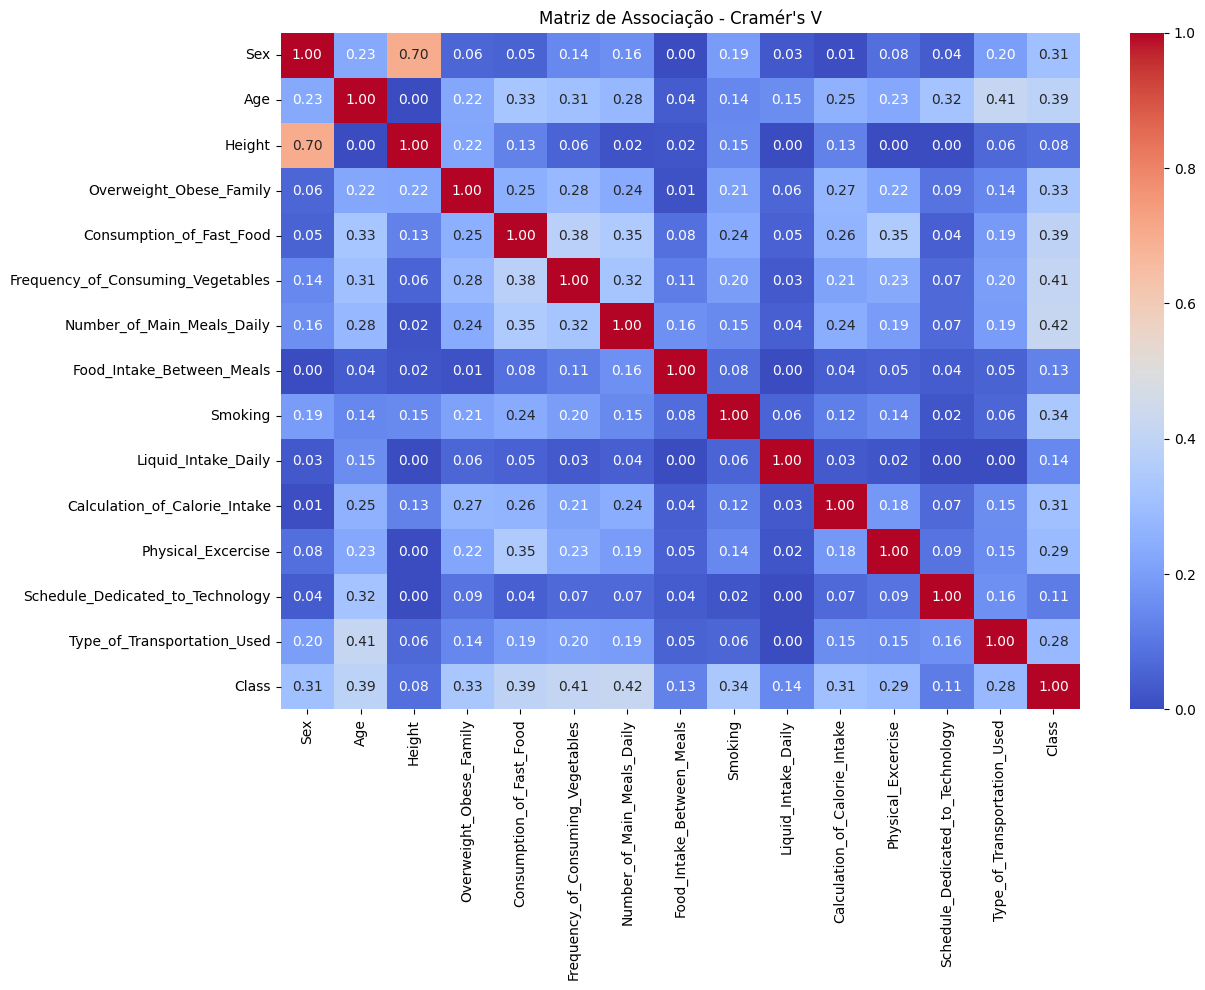

In [ ]:
def cramers_v(x, y):
    confusion_matrix = pd.crosstab(x, y)

    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()

    r, k = confusion_matrix.shape

    phi2 = chi2 / n

    # Correção de viés de Bergsma
    phi2_corr = max(0, phi2 - ((k - 1) * (r - 1)) / (n - 1))
    r_corr = r - ((r - 1) ** 2) / (n - 1)
    k_corr = k - ((k - 1) ** 2) / (n - 1)

    return np.sqrt(phi2_corr / min(k_corr - 1, r_corr - 1))


# Matriz de associação
df_cat = df.astype('category')

colunas = df_cat.columns

matriz = pd.DataFrame(
    np.zeros((len(colunas), len(colunas))),
    index=colunas,
    columns=colunas
)

for col1 in colunas:
    for col2 in colunas:
        matriz.loc[col1, col2] = cramers_v(
            df_cat[col1], df_cat[col2]
        )

# Heatmap
plt.figure(figsize=(13, 10))

sns.heatmap(
    matriz,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=0,
    vmax=1
)

plt.title("Matriz de Associação - Cramér's V")
plt.tight_layout()
plt.show()

- A matriz de Cramér's V acima evidencia que, no dataset, não há associação forte da obesidade com altura, consumo de alimentos entre as refeições, consumo de líquidos e uso de tecnologia.

- Já as outras variáveis apresentam, aproximadamente, associação entre 0.3 e 0.4 com a obesidade.

- Destaca-se a forte associação entre sexo e altura, conforme esperado.

- Vamos explorar mais essas associações com testes estatísticos.

## **Testes de associação com variáveis categóricas**

In [ ]:
# Variáveis categóricas explicativas
variaveis = [
    c for c in df.columns
    if c not in ['Age', 'Height', 'Class']
]

resultados = []

for variavel in variaveis:

    # Tabela de contingência
    dados = df[[variavel, 'Class']].dropna()

    tabela = pd.crosstab(
        dados[variavel],
        dados['Class']
    )

    # Verifica se existem categorias suficientes
    if min(tabela.shape) < 2:
        continue

    # Teste qui-quadrado
    chi2, p, gl, esperados = chi2_contingency(
        tabela,
        correction=False
    )

    n = tabela.to_numpy().sum()
    r, k = tabela.shape

    # Cramér's V com correção de viés
    phi2 = chi2 / n

    phi2_corr = max(
        0,
        phi2 - ((k - 1) * (r - 1)) / (n - 1)
    )

    r_corr = r - ((r - 1) ** 2) / (n - 1)
    k_corr = k - ((k - 1) ** 2) / (n - 1)

    denominador = min(k_corr - 1, r_corr - 1)

    cramers_v = (
        np.sqrt(phi2_corr / denominador)
        if denominador > 0 else np.nan
    )

    # Avaliação das frequências esperadas
    porcentagem_abaixo_5 = (
        (esperados < 5).sum() / esperados.size * 100
    )

    resultados.append({
        'Variável': variavel,
        'Qui-quadrado': chi2,
        'GL': gl,
        'p-valor': p,
        "Cramér's V": cramers_v,
        'Esperadas < 5 (%)': porcentagem_abaixo_5,
        'Menor frequência esperada': esperados.min()
    })


# Organiza os resultados
resultado_chi = pd.DataFrame(resultados)

# Correção de Holm para comparações múltiplas
if not resultado_chi.empty:

    resultado_chi['p-valor (Holm)'] = multipletests(
        resultado_chi['p-valor'],
        alpha=alpha,
        method='holm'
    )[1]

    resultado_chi['Significância'] = np.where(
        resultado_chi['p-valor (Holm)'] < alpha,
        'Significativo',
        'Não significativo'
    )

    resultado_chi = resultado_chi.sort_values(
        'p-valor (Holm)'
    )


# Impressão dos resultados
print('\n' + '=' * 125)
print('       TESTES QUI-QUADRADO E CRAMÉR\'S V — ASSOCIAÇÃO COM CLASS')
print('=' * 125)

print(resultado_chi.to_string(
    index=False,
    formatters={
        'Qui-quadrado': lambda x: f'{x:.4f}',
        'p-valor': lambda x: f'{x:.4e}',
        'p-valor (Holm)': lambda x: f'{x:.4e}',
        "Cramér's V": lambda x: f'{x:.4f}',
        'Esperadas < 5 (%)': lambda x: f'{x:.2f}%',
        'Menor frequência esperada': lambda x: f'{x:.3f}'
    }
))

print('\n' + '=' * 125)
print('H₀: Não existe associação entre a variável e a classificação.')
print('H₁: Existe associação entre a variável e a classificação.')
print(f'Nível de significância: α = {alpha}')
print('Correção para comparações múltiplas: Holm')
print('=' * 125)

print(
    '\nVariáveis com associação estatisticamente significativa:',
    (resultado_chi['p-valor (Holm)'] < alpha).sum()
)


       TESTES QUI-QUADRADO E CRAMÉR'S V — ASSOCIAÇÃO COM CLASS
                         Variável Qui-quadrado  GL     p-valor Cramér's V Esperadas < 5 (%) Menor frequência esperada p-valor (Holm) Significância
       Number_of_Main_Meals_Daily     576.6152   6 2.5781e-121     0.4212             0.00%                    10.791    3.0938e-120 Significativo
Frequency_of_Consuming_Vegetables     554.6705   6 1.3897e-116     0.4130             0.00%                    18.137    1.5287e-115 Significativo
               Physical_Excercise     409.9477  12  2.9579e-80     0.2873             0.00%                     9.340     2.9579e-79 Significativo
      Type_of_Transportation_Used     398.4948  12  7.8835e-78     0.2831             5.00%                     4.262     7.0951e-77 Significativo
         Consumption_of_Fast_Food     250.0021   3  6.5368e-54     0.3918             0.00%                    19.769     5.2294e-53 Significativo
                          Smoking     185.4534   3  5.

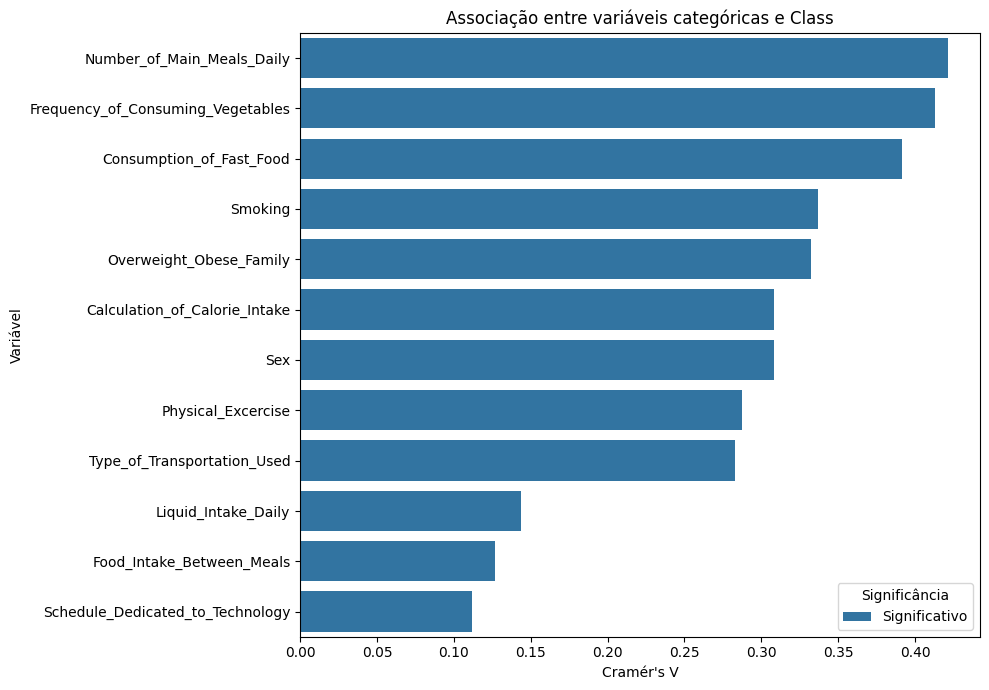

In [ ]:
plt.figure(figsize=(10, 7))

resultado_chi_ordenado = resultado_chi.sort_values(
    by="Cramér's V",
    ascending=False
)

sns.barplot(
    data=resultado_chi_ordenado,
    x="Cramér's V",
    y="Variável",
    hue="Significância",
    dodge=False
)

plt.title("Associação entre variáveis categóricas e Class")
plt.xlabel("Cramér's V")
plt.ylabel("Variável")

plt.tight_layout()
plt.show()

- A associação entre as variáveis categóricas explicativas e a classificação de obesidade foi investigada por meio do teste qui-quadrado de independência, utilizando-se o coeficiente V de Cramér para quantificar a intensidade das associações. Os resultados indicaram associações estatisticamente significativas para todas as 12 variáveis analisadas, mesmo após a aplicação da correção de Holm para comparações múltiplas.

- As maiores intensidades de associação foram observadas para o número de refeições principais (V = 0,4212), a frequência de consumo de vegetais (V = 0,4130) e o consumo de fast food (V = 0,3918).

- Por outro lado, o tempo dedicado à tecnologia (V = 0,1120), o consumo de alimentos entre refeições (V = 0,1270) e a ingestão diária de líquidos (V = 0,1439) apresentaram associações de menor intensidade.

- Esses resultados evidenciam que diferentes características comportamentais e demográficas estão associadas à classificação de obesidade na amostra estudada, embora não permitam estabelecer relações causais.

- Vamos estudar mais à fundo a variável categórica 'Consumption_of_Fast_Food'.

In [ ]:
variavel = 'Consumption_of_Fast_Food'

# Tabela de contingência
tabela = pd.crosstab(
    df[variavel],
    df['Class']
)

# Qui-quadrado
chi2, p, gl, esperados = chi2_contingency(
    tabela,
    correction=False
)

# Resíduos padronizados ajustados
n = tabela.to_numpy().sum()

proporcao_linha = tabela.sum(axis=1).values / n
proporcao_coluna = tabela.sum(axis=0).values / n

residuos = (
    tabela.to_numpy() - esperados
) / np.sqrt(
    esperados *
    (1 - proporcao_linha[:, None]) *
    (1 - proporcao_coluna[None, :])
)

residuos = pd.DataFrame(
    residuos,
    index=tabela.index,
    columns=tabela.columns
)

print('\nRESÍDUOS PADRONIZADOS AJUSTADOS')
print(residuos.to_string(float_format=lambda x: f'{x:.3f}'))

print('\nValores com |resíduo| > 1.96:')
print((residuos.abs() > 1.96))


RESÍDUOS PADRONIZADOS AJUSTADOS
Class                     Underweight  Normal  Overweight  Obesity
Consumption_of_Fast_Food                                          
1.0                            -3.172 -12.913       4.616   12.496
2.0                             3.172  12.913      -4.616  -12.496

Valores com |resíduo| > 1.96:
Class                     Underweight  Normal  Overweight  Obesity
Consumption_of_Fast_Food                                          
1.0                              True    True        True     True
2.0                              True    True        True     True


In [ ]:
# Calcula p-valores bilaterais dos resíduos
z = residuos.to_numpy().flatten()

p_valores = 2 * norm.sf(np.abs(z))

# Correção de Holm
p_ajustados = multipletests(
    p_valores,
    method='holm'
)[1]

p_ajustados = pd.DataFrame(
    p_ajustados.reshape(residuos.shape),
    index=residuos.index,
    columns=residuos.columns
)

print('\nP-VALORES AJUSTADOS PELO MÉTODO DE HOLM')
print(p_ajustados.to_string(float_format=lambda x: f'{x:.6e}'))


P-VALORES AJUSTADOS PELO MÉTODO DE HOLM
Class                     Underweight       Normal   Overweight      Obesity
Consumption_of_Fast_Food                                                    
1.0                      3.022725e-03 3.022804e-37 1.568485e-05 4.696614e-35
2.0                      3.022725e-03 3.022804e-37 1.568485e-05 4.696614e-35



DISTRIBUIÇÃO DE FAST FOOD POR CLASSE (%)
Class                     Underweight  Normal  Overweight  Obesity
Consumption_of_Fast_Food                                          
1.0                             10.96    9.88       33.78    56.79
2.0                             89.04   90.12       66.22    43.21


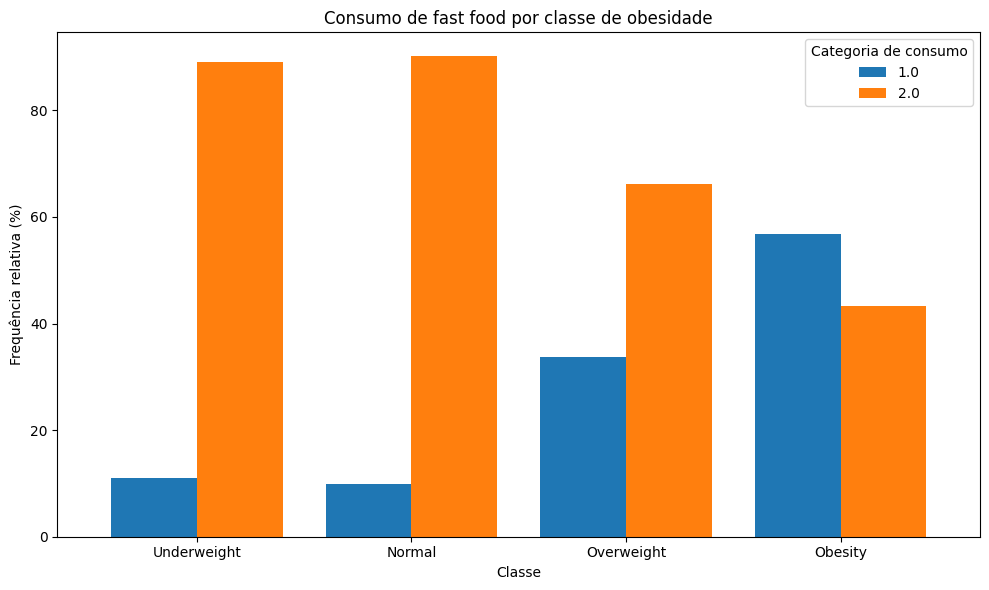

In [ ]:
# Distribuição percentual dentro de cada classe
proporcoes = pd.crosstab(
    df[variavel],
    df['Class'],
    normalize='columns'
) * 100

print('\nDISTRIBUIÇÃO DE FAST FOOD POR CLASSE (%)')
print(proporcoes.round(2).to_string())

# Gráfico
proporcoes.T.plot(
    kind='bar',
    figsize=(10, 6),
    width=0.8
)

plt.title('Consumo de fast food por classe de obesidade')
plt.xlabel('Classe')
plt.ylabel('Frequência relativa (%)')
plt.xticks(rotation=0)
plt.legend(title='Categoria de consumo')
plt.tight_layout()
plt.show()

- A análise dos resíduos padronizados ajustados para a variável Consumption_of_Fast_Food revelou desvios estatisticamente relevantes em todas as combinações entre suas categorias e as classes de obesidade. Observou-se que a categoria 1 apresentou frequências inferiores às esperadas nas classes Underweight e Normal, enquanto apresentou frequências superiores às esperadas nas classes Overweight e Obesity. Para a categoria 2, verificou-se o padrão inverso. Os maiores desvios foram observados nas classes Normal (−12,913) e Obesity (+12,496) para a categoria 1.

- Esses resultados permitem identificar quais combinações de categorias contribuem para a associação detectada pelo teste qui-quadrado.

## **Testes de associação com variáveis quantitativas (idade e altura)**


       CORRELAÇÕES COM A CLASSIFICAÇÃO DE OBESIDADE
Variável Pearson (r) p-valor (Pearson) Significância (Pearson) Spearman (ρ) p-valor (Spearman) Significância (Spearman)    N
     Age      0.5798       2.8996e-145           Significativo       0.6134        4.8773e-167            Significativo 1610
  Height      0.1616        7.0060e-11           Significativo       0.1589         1.4522e-10            Significativo 1610

H₀: Ausência de associação entre as variáveis.
Nível de significância: α = 0.05


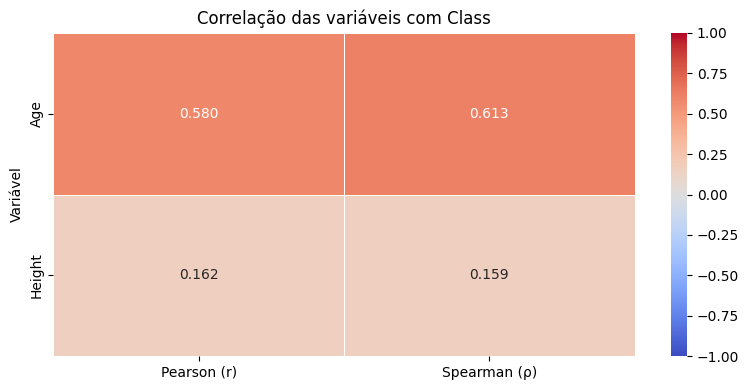

In [ ]:
# Codificação ordinal da variável Class
mapeamento = {
    'underweight': 1,
    'normal': 2,
    'overweight': 3,
    'obesity': 4,
}

def codificar_classe(x):
    if isinstance(x, bytes):
        x = x.decode('utf-8')

    x = str(x).strip().lower()

    if x in mapeamento:
        return mapeamento[x]

    return int(x) if x in ['1', '2', '3', '4'] else np.nan


df_corr = df[['Age', 'Height']].copy()
df_corr['Class'] = df['Class'].apply(codificar_classe)

if df_corr['Class'].isna().any():
    raise ValueError("Existem categorias de Class não reconhecidas.")

# Variáveis explicativas
variaveis = ['Age', 'Height']

resultados = []

for variavel in variaveis:

    dados = df_corr[[variavel, 'Class']].dropna()

    # Pearson
    r, p_pearson = pearsonr(
        dados[variavel],
        dados['Class']
    )

    # Spearman
    rho, p_spearman = spearmanr(
        dados[variavel],
        dados['Class']
    )

    resultados.append({
        'Variável': variavel,
        'Pearson (r)': r,
        'p-valor (Pearson)': p_pearson,
        'Significância (Pearson)': (
            'Significativo' if p_pearson < alpha
            else 'Não significativo'
        ),
        'Spearman (ρ)': rho,
        'p-valor (Spearman)': p_spearman,
        'Significância (Spearman)': (
            'Significativo' if p_spearman < alpha
            else 'Não significativo'
        ),
        'N': len(dados)
    })


# Tabela de resultados
resultado_corr = pd.DataFrame(resultados)

print('\n' + '=' * 105)
print('       CORRELAÇÕES COM A CLASSIFICAÇÃO DE OBESIDADE')
print('=' * 105)

print(resultado_corr.to_string(
    index=False,
    formatters={
        'Pearson (r)': lambda x: f'{x:.4f}',
        'p-valor (Pearson)': lambda x: f'{x:.4e}',
        'Spearman (ρ)': lambda x: f'{x:.4f}',
        'p-valor (Spearman)': lambda x: f'{x:.4e}'
    }
))

print('\n' + '=' * 105)
print('H₀: Ausência de associação entre as variáveis.')
print(f'Nível de significância: α = {alpha}')
print('=' * 105)


# Visualização dos coeficientes
matriz_corr = resultado_corr.set_index('Variável')[
    ['Pearson (r)', 'Spearman (ρ)']
]

plt.figure(figsize=(8, 4))

sns.heatmap(
    matriz_corr,
    annot=True,
    cmap='coolwarm',
    fmt='.3f',
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    center=0
)

plt.title('Correlação das variáveis com Class')
plt.tight_layout()
plt.show()

- As correlações de Pearson e de Spearman, juntamente com os seus testes estatísticos de significância, apontam correlação das variáveis idade e altura com a classe de peso dos indivíduos, embora a correlação com a altura seja bem menor.

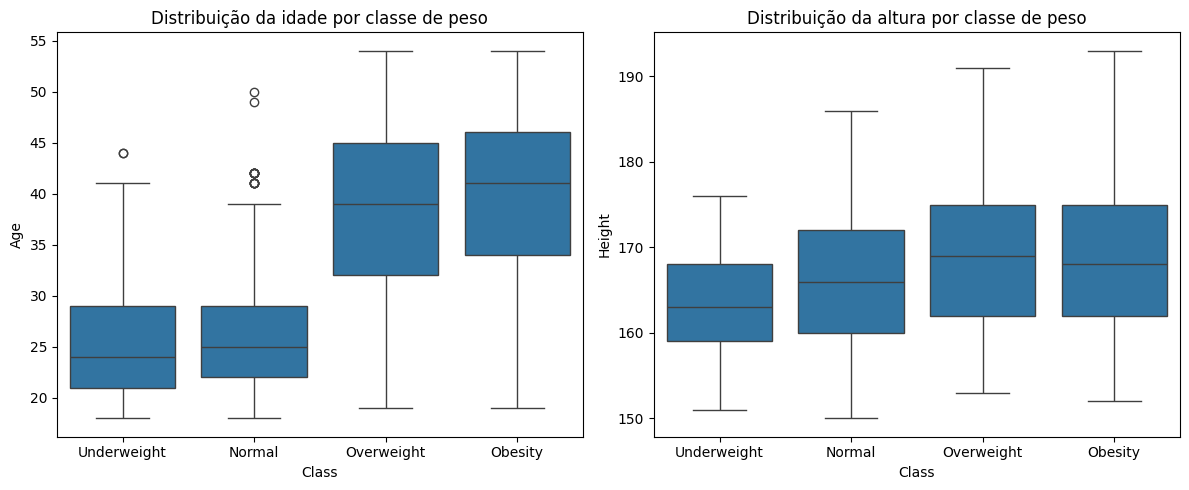

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(data=df, x='Class', y='Age', ax=axes[0])
sns.boxplot(data=df, x='Class', y='Height', ax=axes[1])

axes[0].set_title('Distribuição da idade por classe de peso')
axes[1].set_title('Distribuição da altura por classe de peso')

plt.tight_layout()
plt.show()

- Os boxplots de idade e de altura agrupados por classe de peso mostram diferenças visuais de distribuição.
- Vamos analisar se há diferença significativa entre os grupos utilizando um teste de comparação de múltiplos grupos (assumidos independentes entre si).
- Para decidir qual teste estatístico utilizar, vamos analisar a normalidade e a heterocedasticidade dos dados.


       TESTES DE NORMALIDADE E HOMOGENEIDADE DAS VARIÂNCIAS

VARIÁVEL: Age
-----------------------------------------------------------------------------------------------------------------------------
Shapiro-Wilk:
  Estatística W: 0.99160
  p-valor:       5.705217e-08
  Resultado:    Rejeita normalidade

Levene (centrado na mediana):
  Estatística:  47.92856
  p-valor:      1.153966e-29
  Resultado:    Heterocedasticidade detectada

VARIÁVEL: Height
-----------------------------------------------------------------------------------------------------------------------------
Shapiro-Wilk:
  Estatística W: 0.98565
  p-valor:       1.425724e-11
  Resultado:    Rejeita normalidade

Levene (centrado na mediana):
  Estatística:  7.09044
  p-valor:      9.854011e-05
  Resultado:    Heterocedasticidade detectada

Hipótese nula: normalidade dos resíduos e igualdade das variâncias.
Nível de significância: α = 0.05


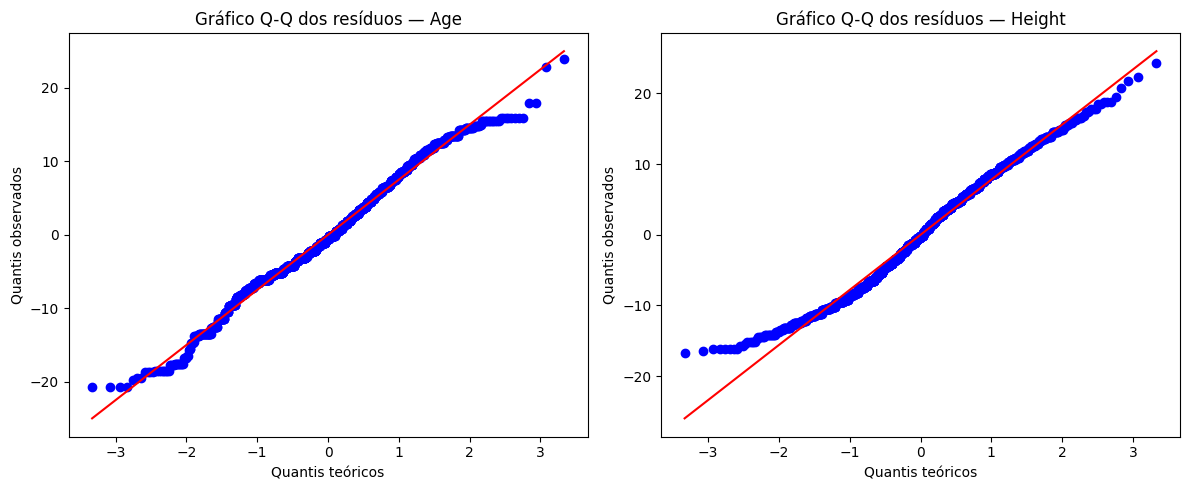

In [ ]:
# Configurações
variaveis = ['Age', 'Height']

resultados = []

for variavel in variaveis:

    # Remove observações ausentes
    dados = df[['Class', variavel]].dropna()

    # Separa os grupos
    grupos = [
        grupo[variavel].values
        for _, grupo in dados.groupby('Class', observed=True)
    ]

    # Calcula os resíduos do modelo ANOVA de uma via
    medias = dados.groupby('Class', observed=True)[variavel].transform('mean')
    residuos = dados[variavel] - medias

    # Teste de normalidade de Shapiro-Wilk
    stat_shapiro, p_shapiro = shapiro(residuos)

    # Teste de homogeneidade das variâncias de Levene
    stat_levene, p_levene = levene(*grupos, center='median')

    # Interpretação
    normalidade = (
        'Não rejeita normalidade'
        if p_shapiro >= alpha
        else 'Rejeita normalidade'
    )

    homogeneidade = (
        'Variâncias homogêneas'
        if p_levene >= alpha
        else 'Heterocedasticidade detectada'
    )

    # Resultado para tabela
    resultados.append({
        'Variável': variavel,
        'Shapiro-Wilk (W)': stat_shapiro,
        'p-valor (Shapiro)': p_shapiro,
        'Normalidade': normalidade,
        'Levene (W)': stat_levene,
        'p-valor (Levene)': p_levene,
        'Homogeneidade': homogeneidade
    })


# Organiza os resultados
tabela = pd.DataFrame(resultados)

print('\n' + '=' * 125)
print('       TESTES DE NORMALIDADE E HOMOGENEIDADE DAS VARIÂNCIAS')
print('=' * 125)

for _, linha in tabela.iterrows():

    print(f"\nVARIÁVEL: {linha['Variável']}")
    print('-' * 125)

    print(f"Shapiro-Wilk:")
    print(f"  Estatística W: {linha['Shapiro-Wilk (W)']:.5f}")
    print(f"  p-valor:       {linha['p-valor (Shapiro)']:.6e}")
    print(f"  Resultado:    {linha['Normalidade']}")

    print(f"\nLevene (centrado na mediana):")
    print(f"  Estatística:  {linha['Levene (W)']:.5f}")
    print(f"  p-valor:      {linha['p-valor (Levene)']:.6e}")
    print(f"  Resultado:    {linha['Homogeneidade']}")

print('\n' + '=' * 125)
print(f'Hipótese nula: normalidade dos resíduos e igualdade das variâncias.')
print(f'Nível de significância: α = {alpha}')
print('=' * 125)


# Gráficos Q-Q dos resíduos
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, variavel in zip(axes, variaveis):

    dados = df[['Class', variavel]].dropna()

    medias = dados.groupby(
        'Class', observed=True
    )[variavel].transform('mean')

    residuos = dados[variavel] - medias

    probplot(residuos, dist='norm', plot=ax)

    ax.set_title(f'Gráfico Q-Q dos resíduos — {variavel}')
    ax.set_xlabel('Quantis teóricos')
    ax.set_ylabel('Quantis observados')

plt.tight_layout()
plt.show()

- Realizamos os testes Shapiro-Wilk e Levene, este último centrado na mediana.

- Para ambas as variáveis analisadas, idade e altura, foram identificadas violações estatisticamente significativas da normalidade dos resíduos e da homogeneidade das variâncias (p < 0,05).

- Dessa forma, optou-se pela utilização do teste não paramétrico de Kruskal-Wallis, seguido de comparações múltiplas pelo teste de Dunn.

In [ ]:
variaveis = ['Age', 'Height']

resultados = []

for variavel in variaveis:

    # Separa as observações por classe
    grupos = [
        grupo[variavel].dropna().values
        for _, grupo in df.groupby('Class', observed=True)
    ]

    # Teste de Kruskal-Wallis
    H, p_value = kruskal(*grupos)

    # Cálculo do tamanho do efeito: Epsilon quadrado
    n = sum(len(g) for g in grupos)
    epsilon2 = H / (n - 1)

    # Interpretação aproximada do tamanho do efeito
    if epsilon2 < 0.01:
        magnitude = 'Desprezível'
    elif epsilon2 < 0.08:
        magnitude = 'Pequeno'
    elif epsilon2 < 0.26:
        magnitude = 'Moderado'
    else:
        magnitude = 'Grande'

    resultados.append({
        'Variável': variavel,
        'H': H,
        'p-valor': p_value,
        'Epsilon²': epsilon2,
        'Tamanho do efeito': magnitude,
        'Conclusão': 'Significativo' if p_value < alpha else 'Não significativo'
    })


# Organiza os resultados
tabela = pd.DataFrame(resultados)

print('\n' + '=' * 100)
print('       TESTE DE KRUSKAL-WALLIS E TAMANHO DO EFEITO')
print('=' * 100)

print(tabela.to_string(
    index=False,
    formatters={
        'H': lambda x: f'{x:.4f}',
        'p-valor': lambda x: f'{x:.4e}',
        'Epsilon²': lambda x: f'{x:.4f}'
    }
))

print('\n' + '-' * 100)
print(f'Número de observações: {len(df)}')
print(f'Número de grupos: {df["Class"].nunique()}')
print(f'Nível de significância: α = {alpha}')
print('Medida de tamanho do efeito: Epsilon quadrado (ε²)')
print('=' * 100)


       TESTE DE KRUSKAL-WALLIS E TAMANHO DO EFEITO
Variável        H     p-valor Epsilon² Tamanho do efeito     Conclusão
     Age 684.5574 4.6831e-148   0.4255            Grande Significativo
  Height  53.8551  1.2048e-11   0.0335           Pequeno Significativo

----------------------------------------------------------------------------------------------------
Número de observações: 1610
Número de grupos: 4
Nível de significância: α = 0.05
Medida de tamanho do efeito: Epsilon quadrado (ε²)


- O teste de Kruskal-Wallis mostra que pelo menos um grupo se difere do resto no quesito de distribuição de idade e de altura.
- Para descobrir quais pares de grupos apresentam diferenças significativas, aplicamos o teste post-hoc de Dunn com correção de Holm.

In [ ]:
for variavel in ['Age', 'Height']:

    # Teste post-hoc de Dunn com correção de Holm
    dunn = sp.posthoc_dunn(
        df,
        val_col=variavel,
        group_col='Class',
        p_adjust='holm'
    )

    # Utiliza diretamente as categorias encontradas
    classes = dunn.index.tolist()

    if len(classes) < 2:
        print(f'Categorias insuficientes para analisar {variavel}.')
        continue

    # Medianas por grupo
    medianas = df.groupby('Class', observed=True)[variavel].median()

    resultados = []

    for c1, c2 in combinations(classes, 2):

        p = dunn.loc[c1, c2]

        med1 = medianas.loc[c1]
        med2 = medianas.loc[c2]

        if p < alpha:
            if med1 > med2:
                tendencia = f'Mediana descritivamente maior em {c1}'
            elif med2 > med1:
                tendencia = f'Mediana descritivamente maior em {c2}'
            else:
                tendencia = 'Medianas descritivamente iguais'

            conclusao = f'Diferença significativa — {tendencia}'
        else:
            conclusao = 'Sem diferença significativa'

        resultados.append({
            'Comparação': f'{c1} × {c2}',
            'Mediana 1': med1,
            'Mediana 2': med2,
            'p-valor ajustado': p,
            'Conclusão': conclusao
        })

    tabela = pd.DataFrame(resultados)

    print('\n' + '=' * 115)
    print(f'       TESTE POST-HOC DE DUNN — {variavel.upper()}')
    print('=' * 115)

    print(tabela.to_string(
        index=False,
        formatters={
            'Mediana 1': lambda x: f'{x:.3f}',
            'Mediana 2': lambda x: f'{x:.3f}',
            'p-valor ajustado': lambda x: f'{x:.4e}'
        }
    ))

    significativos = (tabela['p-valor ajustado'] < alpha).sum()

    print('\n' + '-' * 115)
    print(f'Comparações realizadas: {len(tabela)}')
    print(f'Diferenças significativas: {significativos}/{len(tabela)}')
    print(f'Diferenças não significativas: {len(tabela) - significativos}/{len(tabela)}')
    print(f'Nível de significância: α = {alpha}')
    print('Correção para comparações múltiplas: Holm')
    print('=' * 115)


       TESTE POST-HOC DE DUNN — AGE
              Comparação Mediana 1 Mediana 2 p-valor ajustado                                                             Conclusão
    Underweight × Normal    24.000    25.000       8.0178e-01                                           Sem diferença significativa
Underweight × Overweight    24.000    39.000       2.6345e-25 Diferença significativa — Mediana descritivamente maior em Overweight
   Underweight × Obesity    24.000    41.000       3.5691e-26    Diferença significativa — Mediana descritivamente maior em Obesity
     Normal × Overweight    25.000    39.000      8.9995e-111 Diferença significativa — Mediana descritivamente maior em Overweight
        Normal × Obesity    25.000    41.000       3.0303e-83    Diferença significativa — Mediana descritivamente maior em Obesity
    Overweight × Obesity    39.000    41.000       3.1324e-01                                           Sem diferença significativa

--------------------------------------

- Uma interpretação do teste post-hoc de Dunn acima é que, em geral, classes de maiores pesos apresentam maior idade e maior altura.

- Entretanto, é importante ressaltar que a diferença é maior para a idade do que para a altura (análise do epsilon quadrado).

## **Tentativa de regressão logística ordinal (falhou)**

Inicialmente, ajustamos um modelo de regressão logística ordinal, adequado à natureza ordenada das categorias de classificação do estado nutricional. Entretanto, sua aplicação depende da hipótese de chances proporcionais, que estabelece que os efeitos dos preditores são constantes entre os diferentes pontos de corte da variável resposta.

Essa hipótese foi avaliada por meio de testes de Wald. Os resultados indicaram sua violação ($p < 0{,}05$). Portanto, a regressão logística ordinal não se mostrou adequada aos dados, e optamos por utilizar a regressão logística multinomial, que não exige essa suposição.

In [ ]:
# Ordem da variável resposta ordinal
ordem_classes = [
    'Underweight',
    'Normal',
    'Overweight',
    'Obesity'
]

# Normalização dos valores
def normalizar_valor(x):

    if pd.isna(x):
        return np.nan

    if isinstance(x, bytes):
        x = x.decode('utf-8')

    if isinstance(x, (float, np.floating)) and x.is_integer():
        return str(int(x))

    return str(x).strip()


# Mapeamento da variável Class
mapeamento = {
    '1': 'Underweight',
    '2': 'Normal',
    '3': 'Overweight',
    '4': 'Obesity',
    'underweight': 'Underweight',
    'normal': 'Normal',
    'overweight': 'Overweight',
    'obesity': 'Obesity'
}


def codificar_class(x):

    valor = normalizar_valor(x).lower()

    if valor not in mapeamento:
        raise ValueError(f'Classe desconhecida: {valor}')

    return mapeamento[valor]


# Variáveis quantitativas e categóricas
numericas = ['Age', 'Height']

categoricas = [
    'Sex',
    'Overweight_Obese_Family',
    'Consumption_of_Fast_Food',
    'Smoking',
    'Calculation_of_Calorie_Intake',
    'Liquid_Intake_Daily',
    'Number_of_Main_Meals_Daily',
    'Frequency_of_Consuming_Vegetables',
    'Schedule_Dedicated_to_Technology',
    'Food_Intake_Between_Meals',
    'Physical_Excercise',
    'Type_of_Transportation_Used'
]

# Preparação do DataFrame
df_reg = df[['Class'] + numericas + categoricas].copy()

df_reg['Class'] = df_reg['Class'].apply(codificar_class)

for coluna in numericas:
    df_reg[coluna] = pd.to_numeric(
        df_reg[coluna], errors='coerce'
    )

for coluna in categoricas:
    df_reg[coluna] = df_reg[coluna].apply(normalizar_valor)

# Remoção de valores ausentes e infinitos
df_reg = (
    df_reg
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
)

# Definição da variável resposta ordinal
df_reg['Class'] = pd.Categorical(
    df_reg['Class'],
    categories=ordem_classes,
    ordered=True
)

print(f'Observações utilizadas: {len(df_reg)}')
print('Preparação dos dados concluída.')

Observações utilizadas: 1610
Preparação dos dados concluída.


In [ ]:
# Variáveis quantitativas
X_num = pd.DataFrame({
    'Age_10y': (df_reg['Age'] - df_reg['Age'].mean()) / 10,
    'Height_10cm': (df_reg['Height'] - df_reg['Height'].mean()) / 10
}, index=df_reg.index)

# Variáveis categóricas
X_cat = pd.get_dummies(
    df_reg[categoricas],
    drop_first=True,
    dtype=float
)

# Matriz explicativa
X = pd.concat([X_num, X_cat], axis=1)

# Variável resposta
y = df_reg['Class']

# Verifica dependência linear
if np.linalg.matrix_rank(X.to_numpy()) < X.shape[1]:
    raise ValueError('Matriz explicativa apresenta dependência linear.')

# Ajusta modelo ordinal
modelo = OrderedModel(
    y,
    X,
    distr='logit'
)

resultado = modelo.fit(
    method='bfgs',
    maxiter=2000,
    disp=False
)

print('\n' + '=' * 85)
print('REGRESSÃO LOGÍSTICA ORDINAL')
print('=' * 85)

print(resultado.summary())

print('\nConvergência:', resultado.mle_retvals.get('converged'))
print(f'AIC: {resultado.aic:.4f}')
print(f'BIC: {resultado.bic:.4f}')
print('=' * 85)


REGRESSÃO LOGÍSTICA ORDINAL
                             OrderedModel Results                             
Dep. Variable:                  Class   Log-Likelihood:                -1144.4
Model:                   OrderedModel   AIC:                             2347.
Method:            Maximum Likelihood   BIC:                             2503.
Date:                Tue, 03 Nov 2026                                         
Time:                        03:36:20                                         
No. Observations:                1610                                         
Df Residuals:                    1581                                         
Df Model:                          26                                         
                                          coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------
Age_10y                                 1.0680      

In [ ]:
# Dados já utilizados no modelo ordinal
X_teste = X.copy()
codigos = y.cat.codes.to_numpy()

n = len(y)
J = len(ordem_classes) - 1

if (codigos < 0).any():
    raise ValueError('Existem categorias ausentes na variável resposta.')

X_valores = X_teste.to_numpy(dtype=float)
colunas_X = list(X_teste.columns)

# Respostas binárias acumulativas:
# Y > 0, Y > 1 e Y > 2
endog = np.concatenate([
    (codigos > corte).astype(int)
    for corte in range(J)
])

# Identificador de cada indivíduo
grupos = np.tile(np.arange(n), J)

# Construção da matriz do modelo GEE
partes = {}
interacoes = []

# Interceptos específicos para cada ponto de corte
for corte in range(J):

    partes[f'Intercepto_{corte}'] = np.concatenate([
        np.full(n, float(j == corte))
        for j in range(J)
    ])

# Coeficientes comuns aos pontos de corte
for i, coluna in enumerate(colunas_X):

    partes[f'Beta_{coluna}'] = np.tile(
        X_valores[:, i],
        J
    )

# Interações que permitem coeficientes diferentes
# nos diferentes pontos de corte
for corte in range(1, J):

    for i, coluna in enumerate(colunas_X):

        nome = f'Interacao_{corte}_{coluna}'

        partes[nome] = np.concatenate([
            X_valores[:, i] if j == corte
            else np.zeros(n)
            for j in range(J)
        ])

        interacoes.append(nome)

Z = pd.DataFrame(partes)

# Ajuste GEE com distribuição binomial
modelo_gee = sm.GEE(
    endog=endog,
    exog=Z,
    groups=grupos,
    family=sm.families.Binomial(),
    cov_struct=sm.cov_struct.Independence()
)

resultado_gee = modelo_gee.fit(
    maxiter=200,
    cov_type='robust'
)

# Teste global de Wald das interações
indices = Z.columns.get_indexer(interacoes)

if (indices < 0).any():
    raise ValueError('Não foi possível identificar todas as interações.')

beta = np.asarray(resultado_gee.params)[indices]

cov = np.asarray(
    resultado_gee.cov_params()
)[np.ix_(indices, indices)]

gl = np.linalg.matrix_rank(cov)

if gl < len(interacoes):
    raise ValueError(
        'Matriz de covariância singular. '
        'O teste global não pode ser interpretado com segurança.'
    )

estatistica = float(
    beta.T @ np.linalg.solve(cov, beta)
)

p_valor = chi2_dist.sf(estatistica, gl)

# Impressão
print('\n' + '=' * 85)
print('       TESTE GLOBAL DE WALD — CHANCES PROPORCIONAIS')
print('=' * 85)

print(f'Estatística de Wald: {estatistica:.4f}')
print(f'Graus de liberdade:  {gl}')
print(f'p-valor:             {p_valor:.6e}')

print('\nHipóteses:')
print('H0: Os coeficientes são iguais nos diferentes pontos de corte.')
print('H1: Pelo menos um coeficiente varia entre os pontos de corte.')

print('\nConclusão:')

if p_valor < alpha:
    print('REJEITAMOS H0.')
    print('Há evidências de violação da hipótese de chances proporcionais.')
else:
    print('NÃO REJEITAMOS H0.')
    print('Não foram encontradas evidências suficientes de violação.')

print(f'\nNível de significância: α = {alpha}')
print('=' * 85)


       TESTE GLOBAL DE WALD — CHANCES PROPORCIONAIS
Estatística de Wald: 7496.1341
Graus de liberdade:  52
p-valor:             0.000000e+00

Hipóteses:
H0: Os coeficientes são iguais nos diferentes pontos de corte.
H1: Pelo menos um coeficiente varia entre os pontos de corte.

Conclusão:
REJEITAMOS H0.
Há evidências de violação da hipótese de chances proporcionais.

Nível de significância: α = 0.05


In [ ]:
# ============================================================
# 1. PREPARAÇÃO DOS DADOS
# ============================================================

X_teste = X.copy().astype(float)

codigos_y = y.cat.codes.to_numpy()

n = len(y)
J = len(y.cat.categories) - 1

# Verificações
if (codigos_y < 0).any():
    raise ValueError('Existem categorias ausentes em Class.')

if X_teste.isna().any().any():
    raise ValueError('Existem valores ausentes em X.')


# ============================================================
# 2. CONSTRUÇÃO DO MODELO GEE
# ============================================================

endog = np.concatenate([
    (codigos_y > corte).astype(int)
    for corte in range(J)
])

grupos = np.tile(np.arange(n), J)

partes = {}

# Interceptos específicos por ponto de corte
for corte in range(J):

    partes[f'Intercepto_{corte}'] = np.concatenate([
        np.full(n, float(j == corte))
        for j in range(J)
    ])

# Coeficientes comuns
for coluna in X_teste.columns:

    partes[f'Comum_{coluna}'] = np.tile(
        X_teste[coluna].to_numpy(),
        J
    )

# Interações entre variáveis e pontos de corte
interacoes_por_variavel = {}

for variavel in ['Age', 'Height'] + categoricas:

    if variavel == 'Age':
        colunas = ['Age_10y']

    elif variavel == 'Height':
        colunas = ['Height_10cm']

    else:
        colunas = [
            c for c in X_teste.columns
            if c.startswith(f'{variavel}_')
        ]

    interacoes_variavel = []

    for corte in range(1, J):

        for coluna in colunas:

            if coluna not in X_teste.columns:
                continue

            nome = f'Interacao_{corte}_{coluna}'

            partes[nome] = np.concatenate([
                X_teste[coluna].to_numpy()
                if j == corte
                else np.zeros(n)
                for j in range(J)
            ])

            interacoes_variavel.append(nome)

    if interacoes_variavel:
        interacoes_por_variavel[variavel] = interacoes_variavel


Z = pd.DataFrame(partes)

# Estimação GEE
modelo_gee = sm.GEE(
    endog=endog,
    exog=Z,
    groups=grupos,
    family=sm.families.Binomial(),
    cov_struct=sm.cov_struct.Independence()
)

resultado_gee = modelo_gee.fit(
    maxiter=200,
    cov_type='robust'
)


# ============================================================
# 3. TESTES INDIVIDUAIS DE WALD
# ============================================================

resultados = []

parametros = resultado_gee.params
covariancia = resultado_gee.cov_params()

for variavel, nomes in interacoes_por_variavel.items():

    # Coeficientes das interações da variável
    beta = parametros.loc[nomes].to_numpy()

    # Matriz de covariância correspondente
    cov = covariancia.loc[nomes, nomes].to_numpy()

    # Graus de liberdade efetivos
    gl = np.linalg.matrix_rank(cov)

    if gl == 0:
        continue

    # Estatística de Wald
    W = beta.T @ np.linalg.pinv(cov) @ beta

    # p-valor
    p = chi2_dist.sf(W, gl)

    resultados.append({
        'Variável': variavel,
        'Estatística Wald': W,
        'GL': gl,
        'p-valor': p
    })


# ============================================================
# 4. CORREÇÃO DE HOLM
# ============================================================

tabela_wald = pd.DataFrame(resultados)

if tabela_wald.empty:
    raise ValueError('Nenhuma variável pôde ser testada.')

tabela_wald['p-valor (Holm)'] = multipletests(
    tabela_wald['p-valor'],
    method='holm'
)[1]

tabela_wald['Conclusão'] = np.where(
    tabela_wald['p-valor (Holm)'] < alpha,
    'Viola a hipótese',
    'Sem evidência de violação'
)

tabela_wald = tabela_wald.sort_values(
    'p-valor (Holm)'
)


# ============================================================
# 5. IMPRESSÃO DOS RESULTADOS
# ============================================================

print('\n' + '=' * 115)
print('       TESTES INDIVIDUAIS DE WALD — CHANCES PROPORCIONAIS')
print('=' * 115)

print(tabela_wald.to_string(
    index=False,
    formatters={
        'Estatística Wald': lambda x: f'{x:.4f}',
        'p-valor': lambda x: f'{x:.4e}',
        'p-valor (Holm)': lambda x: f'{x:.4e}'
    }
))

violacoes = (
    tabela_wald['p-valor (Holm)'] < 0.05
).sum()

total = len(tabela_wald)

print('\n' + '-' * 115)
print(f'Variáveis testadas: {total}')
print(f'Variáveis com evidência de violação: {violacoes}')
print(f'Variáveis sem evidência de violação: {total - violacoes}')
print('Correção para comparações múltiplas: Holm')
print(f'Nível de significância: α = {alpha}')
print('=' * 115)


       TESTES INDIVIDUAIS DE WALD — CHANCES PROPORCIONAIS
                         Variável Estatística Wald  GL    p-valor p-valor (Holm)                 Conclusão
Frequency_of_Consuming_Vegetables        5144.8864   4 0.0000e+00     0.0000e+00          Viola a hipótese
                          Smoking          70.0121   2 6.2671e-16     8.1472e-15          Viola a hipótese
              Liquid_Intake_Daily          57.2221   4 1.1113e-11     1.3336e-10          Viola a hipótese
                              Age          45.8539   2 1.1040e-10     1.2144e-09          Viola a hipótese
        Food_Intake_Between_Meals          55.3942   6 3.8590e-10     3.8590e-09          Viola a hipótese
               Physical_Excercise          57.2295   8 1.6243e-09     1.4619e-08          Viola a hipótese
      Type_of_Transportation_Used          44.1487   8 5.3332e-07     4.2665e-06          Viola a hipótese
         Consumption_of_Fast_Food          21.0868   2 2.6367e-05     1.8457e-04     

## **Regressão logística multinomial**

Diante da violação da hipótese de chances proporcionais na regressão logística ordinal, optou-se pela regressão logística multinomial, adotando *Normal* como categoria de referência. Foram consideradas quatro variáveis explicativas: idade, sexo, histórico familiar de sobrepeso ou obesidade e consumo de fast food.

A idade foi incorporada por meio de termos linear e quadrático, uma vez que a comparação entre os modelos indicou melhora significativa do ajuste $$LR = 8{,}8794;\quad p = 0{,}03094$$, sugerindo uma relação não linear com a classificação.

### Avaliação do modelo

O modelo foi estimado por máxima verossimilhança, apresentando convergência satisfatória para as 1.610 observações. O teste global da razão de verossimilhanças indicou que o conjunto de variáveis explicativas contribui significativamente para o ajuste $$LR = 1136{,}0819;\quad p < 0{,}001$$.

Após a correção de Holm, todas as variáveis apresentaram contribuições estatisticamente significativas: idade, sexo, histórico familiar e consumo de fast food. Os valores de VIF variaram entre 1,0598 e 1,3009, não indicando problemas relevantes de multicolinearidade.

### Principais resultados

A interpretação dos parâmetros foi realizada por meio das razões de risco relativo (*Relative Risk Ratios*, RRR), com intervalos de confiança de 95%.

A idade apresentou associação positiva e estatisticamente significativa com as classes *Overweight* e *Obesity*. Como sua relação com a classificação foi modelada quadraticamente, os RRR foram avaliados para incrementos de dez anos em diferentes pontos da distribuição etária.

Para *Overweight* em relação a *Normal*, os RRR foram de 6,8625, 10,8331 e 19,4835, considerando incrementos iniciados aos 25, 32 e 41 anos, respectivamente. Para *Obesity*, os valores foram de 6,7624, 11,7687 e 23,9942. Esses resultados sugerem que a associação entre idade e classes de maior peso apresenta magnitude crescente nos pontos etários investigados.

Na comparação entre *Underweight* e *Normal*, não foram identificadas associações estatisticamente significativas para a idade após a correção de Holm.

Quanto às variáveis categóricas, o sexo e o consumo de fast food apresentaram associações significativas nas comparações envolvendo *Overweight* e *Obesity*. A ausência de consumo de fast food esteve associada a menores razões relativas de pertencimento a essas classes, em comparação com a categoria de referência, mantendo as demais variáveis constantes.

O histórico familiar apresentou associação estatisticamente significativa apenas na comparação entre *Obesity* e *Normal*, com RRR de 0,2221 para a categoria correspondente à ausência de histórico familiar. Esse resultado indica menor razão relativa de pertencimento à classe *Obesity* em comparação com *Normal*, em relação à categoria de referência.

ATENÇÃO: os resultados representam associações condicionais às variáveis incluídas no modelo, não permitindo estabelecer relações causais. Além disso, a hipótese de independência das alternativas irrelevantes (IIA) não foi formalmente avaliada, e a utilização de um modelo reduzido pode deixar fatores de confusão não controlados.

In [ ]:
# ============================================================
# 1. SELEÇÃO DAS VARIÁVEIS
# ============================================================

variaveis_numericas = ['Age']

variaveis_categoricas = [
    'Sex',
    'Overweight_Obese_Family',
    'Consumption_of_Fast_Food'
]

dados_mn = df_reg[
    ['Class'] + variaveis_numericas + variaveis_categoricas
].copy()

# ============================================================
# 2. VARIÁVEL RESPOSTA
# ============================================================

ordem_classes = [
    'Normal',
    'Underweight',
    'Overweight',
    'Obesity'
]

y_mn = pd.Categorical(
    dados_mn['Class'],
    categories=ordem_classes
).codes

if (y_mn < 0).any():
    raise ValueError('Existem classes não reconhecidas.')

# ============================================================
# 3. CONSTRUÇÃO DA MATRIZ EXPLICATIVA
# ============================================================

# Centralização da idade
MEDIA_IDADE = dados_mn['Age'].mean()

idade_10y = (
    dados_mn['Age'] - MEDIA_IDADE
) / 10

# Termos linear e quadrático
X_num = pd.DataFrame({
    'Age_10y': idade_10y,
    'Age_10y_squared': idade_10y**2 - (idade_10y**2).mean()
}, index=dados_mn.index)

# Variáveis categóricas
X_cat = pd.get_dummies(
    dados_mn[variaveis_categoricas].astype(str),
    drop_first=True,
    dtype=float
)

# Modelo linear (para comparação)
X_linear = pd.concat(
    [pd.DataFrame({
        'Age_10y': idade_10y
    }, index=dados_mn.index), X_cat],
    axis=1
)

X_linear = sm.add_constant(X_linear)

# Modelo quadrático (modelo principal)
X_mn = pd.concat([X_num, X_cat], axis=1)

X_mn = sm.add_constant(X_mn)

# Verificação de dependência linear
if np.linalg.matrix_rank(X_mn.to_numpy()) < X_mn.shape[1]:
    raise ValueError('Matriz explicativa apresenta dependência linear.')

# ============================================================
# 4. FUNÇÃO DE ESTIMAÇÃO
# ============================================================

def ajustar_mnlogit(y, X):

    modelo = sm.MNLogit(y, X)

    for metodo in ['lbfgs', 'bfgs', 'newton']:

        try:
            with warnings.catch_warnings():
                warnings.simplefilter('ignore')

                resultado = modelo.fit(
                    method=metodo,
                    maxiter=3000,
                    disp=False
                )

            if resultado.mle_retvals.get('converged', False):
                return resultado

        except Exception:
            continue

    raise RuntimeError('O modelo multinomial não convergiu.')

# ============================================================
# 5. ESTIMAÇÃO DOS MODELOS
# ============================================================

# Modelo linear
resultado_mn_linear = ajustar_mnlogit(
    y_mn,
    X_linear
)

# Modelo quadrático
resultado_mn = ajustar_mnlogit(
    y_mn,
    X_mn
)

# ============================================================
# 6. RESULTADOS
# ============================================================

print('\n' + '=' * 100)
print('REGRESSÃO LOGÍSTICA MULTINOMIAL — MODELO QUADRÁTICO')
print('=' * 100)

print(resultado_mn.summary())

print(f'\nLog-verossimilhança: {resultado_mn.llf:.4f}')
print(f'AIC: {resultado_mn.aic:.4f}')
print(f'BIC: {resultado_mn.bic:.4f}')

print('\nConvergência linear:',
      resultado_mn_linear.mle_retvals.get('converged'))

print('Convergência quadrática:',
      resultado_mn.mle_retvals.get('converged'))

print('=' * 100)


REGRESSÃO LOGÍSTICA MULTINOMIAL — MODELO QUADRÁTICO
                          MNLogit Regression Results                          
Dep. Variable:                      y   No. Observations:                 1610
Model:                        MNLogit   Df Residuals:                     1592
Method:                           MLE   Df Model:                           15
Date:                Tue, 03 Nov 2026   Pseudo R-squ.:                  0.2987
Time:                        03:36:32   Log-Likelihood:                -1333.8
converged:                       True   LL-Null:                       -1901.8
Covariance Type:            nonrobust   LLR p-value:                8.695e-233
                       y=1       coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------
const                         -2.1389      0.593     -3.609      0.000      -3.300      -0.977
Age_10y                       

In [ ]:
# Modelo nulo: somente interceptos
X_nulo = pd.DataFrame(
    {'const': np.ones(len(X_mn))},
    index=X_mn.index
)

resultado_nulo = sm.MNLogit(
    y_mn,
    X_nulo
).fit(method='newton', maxiter=2000, disp=False)

# Teste da razão de verossimilhanças
LR = 2 * (resultado_mn.llf - resultado_nulo.llf)

n_classes = len(np.unique(y_mn))
gl = (X_mn.shape[1] - 1) * (n_classes - 1)

p_valor = chi2_dist.sf(LR, gl)

print('=' * 85)
print('TESTE GLOBAL DE SIGNIFICÂNCIA — REGRESSÃO MULTINOMIAL')
print('=' * 85)

print(f'Estatística LR: {LR:.4f}')
print(f'Graus de liberdade: {gl}')
print(f'p-valor: {p_valor:.6e}')

print(
    'Conclusão: modelo globalmente significativo.'
    if p_valor < alpha
    else 'Conclusão: não há evidências de significância global.'
)

print('=' * 85)

TESTE GLOBAL DE SIGNIFICÂNCIA — REGRESSÃO MULTINOMIAL
Estatística LR: 1136.0819
Graus de liberdade: 15
p-valor: 8.695062e-233
Conclusão: modelo globalmente significativo.


In [ ]:
# Mapeamento dos preditores
mapa_variaveis = {
    'Age': [
        'Age_10y',
        'Age_10y_squared'
    ],

    'Sex': [
        c for c in X_mn.columns
        if c.startswith('Sex_')
    ],

    'Overweight_Obese_Family': [
        c for c in X_mn.columns
        if c.startswith('Overweight_Obese_Family_')
    ],

    'Consumption_of_Fast_Food': [
        c for c in X_mn.columns
        if c.startswith('Consumption_of_Fast_Food_')
    ]
}

resultados = []

for variavel, colunas in mapa_variaveis.items():

    X_reduzido = X_mn.drop(columns=colunas)

    modelo_reduzido = sm.MNLogit(
        y_mn,
        X_reduzido
    ).fit(
        method='newton',
        maxiter=2000,
        disp=False
    )

    LR = 2 * (
        resultado_mn.llf - modelo_reduzido.llf
    )

    gl = len(colunas) * (n_classes - 1)

    p = chi2_dist.sf(max(0, LR), gl)

    resultados.append({
        'Variável': variavel,
        'LR': LR,
        'GL': gl,
        'p-valor': p
    })

resultado_variaveis = pd.DataFrame(resultados)

# Correção de Holm
resultado_variaveis['p-valor (Holm)'] = multipletests(
    resultado_variaveis['p-valor'],
    method='holm'
)[1]

resultado_variaveis['Significância'] = np.where(
    resultado_variaveis['p-valor (Holm)'] < alpha,
    'Significativo',
    'Não significativo'
)

print('\n' + '=' * 105)
print('TESTES DE RAZÃO DE VEROSSIMILHANÇAS — PREDITORES')
print('=' * 105)

print(resultado_variaveis.to_string(
    index=False,
    formatters={
        'LR': lambda x: f'{x:.4f}',
        'p-valor': lambda x: f'{x:.4e}',
        'p-valor (Holm)': lambda x: f'{x:.4e}'
    }
))

print('=' * 105)


TESTES DE RAZÃO DE VEROSSIMILHANÇAS — PREDITORES
                Variável       LR  GL     p-valor p-valor (Holm) Significância
                     Age 636.8387   6 2.6299e-134    1.0519e-133 Significativo
                     Sex  90.6732   3  1.5702e-19     3.1404e-19 Significativo
 Overweight_Obese_Family  70.6639   3  3.0767e-15     3.0767e-15 Significativo
Consumption_of_Fast_Food  98.7315   3  2.9122e-21     8.7367e-21 Significativo


In [ ]:
X_vif = X_mn.drop(columns='const')

X_vif = sm.add_constant(X_vif)

resultados_vif = []

for i, coluna in enumerate(X_vif.columns):

    if coluna == 'const':
        continue

    vif = variance_inflation_factor(
        X_vif.to_numpy(),
        i
    )

    resultados_vif.append({
        'Variável': coluna,
        'VIF': vif
    })

tabela_vif = pd.DataFrame(resultados_vif)

print('\n' + '=' * 75)
print('DIAGNÓSTICO DE MULTICOLINEARIDADE — VIF')
print('=' * 75)

print(tabela_vif.sort_values(
    'VIF', ascending=False
).to_string(
    index=False,
    formatters={'VIF': lambda x: f'{x:.4f}'}
))

print('\nReferência: valores de VIF acima de 5 merecem investigação.')
print('=' * 75)


DIAGNÓSTICO DE MULTICOLINEARIDADE — VIF
                  Variável    VIF
                   Age_10y 1.3009
           Age_10y_squared 1.1788
Consumption_of_Fast_Food_2 1.1369
 Overweight_Obese_Family_2 1.0822
                     Sex_2 1.0598

Referência: valores de VIF acima de 5 merecem investigação.


In [ ]:
coef = resultado_mn.params
erros = resultado_mn.bse

print('\n' + '=' * 85)
print('DIAGNÓSTICO DE ESTABILIDADE DO MODELO')
print('=' * 85)

print('Convergência:',
      resultado_mn.mle_retvals.get('converged'))

print(f'Maior coeficiente absoluto: {np.abs(coef).to_numpy().max():.4f}')
print(f'Maior erro-padrão: {erros.to_numpy().max():.4f}')

print(
    'Coeficientes não finitos:',
    np.sum(~np.isfinite(coef.to_numpy()))
)

print(
    'Erros-padrão não finitos:',
    np.sum(~np.isfinite(erros.to_numpy()))
)

print('=' * 85)


DIAGNÓSTICO DE ESTABILIDADE DO MODELO
Convergência: True
Maior coeficiente absoluto: 2.9155
Maior erro-padrão: 0.5926
Coeficientes não finitos: 0
Erros-padrão não finitos: 0


In [ ]:
# Teste da razão de verossimilhanças
LR = 2 * (
    resultado_mn.llf -
    resultado_mn_linear.llf
)

gl = len(ordem_classes) - 1

p = chi2_dist.sf(max(0, LR), gl)

print('\n' + '=' * 90)
print('TESTE DA FORMA FUNCIONAL — IDADE')
print('=' * 90)

print('Modelo linear vs. modelo quadrático')
print(f'Estatística LR: {LR:.4f}')
print(f'Graus de liberdade: {gl}')
print(f'p-valor: {p:.6e}')

if p < alpha:
    print('\nRESULTADO: O termo quadrático melhora significativamente o ajuste.')
    print('Há evidências de não linearidade na relação entre idade e classificação.')
else:
    print('\nRESULTADO: Não foram encontradas evidências suficientes')
    print('para justificar o termo quadrático.')

print('=' * 90)


TESTE DA FORMA FUNCIONAL — IDADE
Modelo linear vs. modelo quadrático
Estatística LR: 8.8794
Graus de liberdade: 3
p-valor: 3.093764e-02

RESULTADO: O termo quadrático melhora significativamente o ajuste.
Há evidências de não linearidade na relação entre idade e classificação.


In [ ]:
# ============================================================
# 1. CONFIGURAÇÕES
# ============================================================

coef = resultado_mn.params
cov = resultado_mn.cov_params()

z_critico = norm.ppf(0.975)

classes_comparacao = ordem_classes[1:]

resultados = []

# Idades representativas
idades = {
    'Q1': dados_mn['Age'].quantile(0.25),
    'Mediana': dados_mn['Age'].median(),
    'Q3': dados_mn['Age'].quantile(0.75)
}

# ============================================================
# 2. RRR DA IDADE — EFEITO NÃO LINEAR
# ============================================================

for j, classe in enumerate(classes_comparacao):

    codigo = str(j + 1)

    beta1 = coef.loc['Age_10y', j]
    beta2 = coef.loc['Age_10y_squared', j]

    # Covariâncias dos coeficientes
    var1 = cov.loc[
        (codigo, 'Age_10y'),
        (codigo, 'Age_10y')
    ]

    var2 = cov.loc[
        (codigo, 'Age_10y_squared'),
        (codigo, 'Age_10y_squared')
    ]

    cov12 = cov.loc[
        (codigo, 'Age_10y'),
        (codigo, 'Age_10y_squared')
    ]

    for identificador, idade in idades.items():

        x = (idade - MEDIA_IDADE) / 10

        fator = 2 * x + 1

        # Efeito de um aumento de 10 anos
        efeito = beta1 + beta2 * fator

        # Variância pelo método delta
        variancia = (
            var1 +
            fator**2 * var2 +
            2 * fator * cov12
        )

        erro = np.sqrt(max(0, variancia))

        rrr = np.exp(efeito)

        limite_inf = np.exp(
            efeito - z_critico * erro
        )

        limite_sup = np.exp(
            efeito + z_critico * erro
        )

        p = 2 * norm.sf(
            abs(efeito / erro)
        ) if erro > 0 else np.nan

        resultados.append({
            'Classe': classe,
            'Variável': f'Age (+10 anos a partir de {identificador})',
            'Idade inicial': idade,
            'RRR': rrr,
            'IC 95% inferior': limite_inf,
            'IC 95% superior': limite_sup,
            'p-valor': p
        })

# ============================================================
# 3. RRR DAS VARIÁVEIS CATEGÓRICAS
# ============================================================

for j, classe in enumerate(classes_comparacao):

    for variavel in X_mn.columns:

        if variavel in [
            'const',
            'Age_10y',
            'Age_10y_squared'
        ]:
            continue

        beta = coef.loc[variavel, j]

        erro = resultado_mn.bse.loc[variavel, j]

        p = resultado_mn.pvalues.loc[variavel, j]

        resultados.append({
            'Classe': classe,
            'Variável': variavel,
            'Idade inicial': np.nan,
            'RRR': np.exp(beta),
            'IC 95% inferior': np.exp(beta - z_critico * erro),
            'IC 95% superior': np.exp(beta + z_critico * erro),
            'p-valor': p
        })

# ============================================================
# 4. CORREÇÃO DE HOLM
# ============================================================

tabela_rrr = pd.DataFrame(resultados)

tabela_rrr['p-valor (Holm)'] = multipletests(
    tabela_rrr['p-valor'],
    method='holm'
)[1]

tabela_rrr['Significância'] = np.where(
    tabela_rrr['p-valor (Holm)'] < alpha,
    'Significativo',
    'Não significativo'
)

# ============================================================
# 5. IMPRESSÃO
# ============================================================

print('\n' + '=' * 140)
print('REGRESSÃO LOGÍSTICA MULTINOMIAL — MODELO QUADRÁTICO')
print('=' * 140)

for classe in classes_comparacao:

    tabela_classe = tabela_rrr[
        tabela_rrr['Classe'] == classe
    ].drop(columns='Classe')

    print(f'\nCOMPARAÇÃO: {classe} vs. Normal')
    print('-' * 140)

    print(tabela_classe.to_string(
        index=False,
        formatters={
            'Idade inicial': lambda x: f'{x:.1f}' if pd.notna(x) else '-',
            'RRR': lambda x: f'{x:.4f}',
            'IC 95% inferior': lambda x: f'{x:.4f}',
            'IC 95% superior': lambda x: f'{x:.4f}',
            'p-valor': lambda x: f'{x:.4e}',
            'p-valor (Holm)': lambda x: f'{x:.4e}'
        }
    ))

print('\n' + '=' * 140)
print('Categoria de referência: Normal')
print('Idade: RRR para incremento de 10 anos em três pontos da distribuição.')
print('Demais variáveis: comparação com a categoria de referência.')
print('IC: 95% pelo método delta para os efeitos da idade.')
print('Correção de múltiplas comparações: Holm.')
print('=' * 140)


REGRESSÃO LOGÍSTICA MULTINOMIAL — MODELO QUADRÁTICO

COMPARAÇÃO: Underweight vs. Normal
--------------------------------------------------------------------------------------------------------------------------------------------
                          Variável Idade inicial    RRR IC 95% inferior IC 95% superior    p-valor p-valor (Holm)     Significância
     Age (+10 anos a partir de Q1)          25.0 1.0443          0.7185          1.5178 8.2026e-01     1.0000e+00 Não significativo
Age (+10 anos a partir de Mediana)          32.0 2.1160          1.0356          4.3235 3.9784e-02     2.3870e-01 Não significativo
     Age (+10 anos a partir de Q3)          41.0 5.2462          1.2296         22.3832 2.5144e-02     1.7601e-01 Não significativo
                             Sex_2           NaN 1.5672          0.8461          2.9030 1.5316e-01     7.6579e-01 Não significativo
         Overweight_Obese_Family_2           NaN 0.9488          0.3869          2.3264 9.0855e-01     1.0000e

## **Considerações Finais**

A análise evidenciou associações estatisticamente significativas entre a classificação do estado nutricional e todas as 12 variáveis categóricas investigadas, mesmo após a correção de Holm. As maiores associações foram observadas para o número de refeições principais (V = 0,4212), a frequência de consumo de vegetais (V = 0,4130) e o consumo de fast food (V = 0,3918). Entre as variáveis quantitativas, a idade apresentou associação positiva de magnitude moderada a elevada com a classificação (ρ = 0,6134), enquanto a altura apresentou associação fraca (ρ = 0,1589). Os testes de Kruskal-Wallis reforçaram essa diferença: o tamanho do efeito foi grande para idade (ε² = 0,4244), mas pequeno para altura (ε² = 0,0317). As comparações de Dunn mostraram que as classes *Overweight* e *Obesity* apresentaram idades medianas superiores às classes *Underweight* e *Normal*, embora não tenha sido identificada diferença significativa entre *Overweight* e *Obesity*. Para altura, as diferenças entre os grupos foram menos expressivas.

A análise específica do consumo de fast food também revelou um padrão relevante: sua frequência foi proporcionalmente maior nas classes *Overweight* (33,78%) e *Obesity* (56,79%) do que em *Underweight* (10,96%) e *Normal* (9,88%). Esse comportamento foi confirmado pelos resíduos padronizados ajustados. Em conjunto, os resultados apontam que características demográficas e comportamentais estão associadas à classificação nutricional na amostra, mas as magnitudes dessas associações são distintas.

Na etapa de modelagem, a regressão logística ordinal foi descartada devido à violação da hipótese de chances proporcionais, identificada pelo teste global de Wald e por testes individuais para dez das 14 variáveis avaliadas. Assim, adotou-se a regressão logística multinomial, com *Normal* como categoria de referência. O modelo quadrático da idade apresentou melhora significativa em relação ao linear (LR = 8,8794; p = 0,03094), convergiu para as 1.610 observações e foi globalmente significativo (LR = 1.136,0819; p < 0,001). Seu pseudo-\(R^2\) de McFadden foi 0,2987, e os valores de VIF (1,0598 a 1,3009) não indicaram multicolinearidade relevante. Após a correção de Holm, os quatro preditores — idade, sexo, histórico familiar e consumo de fast food — apresentaram contribuição estatisticamente significativa para o modelo.

Os resultados multinomiais indicaram associação positiva entre idade e as classes *Overweight* e *Obesity* em comparação com *Normal*, com razões de risco relativo (RRR) crescentes nos incrementos de dez anos avaliados a partir dos 25, 32 e 41 anos. Sexo e consumo de fast food também apresentaram associações significativas nessas duas comparações. A ausência de histórico familiar de sobrepeso ou obesidade esteve associada a uma menor razão relativa de pertencimento à classe *Obesity*, em comparação com *Normal*, mas não apresentou associação significativa na comparação com *Overweight*. Para *Underweight*, nenhum dos efeitos individuais permaneceu significativo após o ajuste de Holm.

Por fim, os resultados devem ser interpretados como associações condicionais às variáveis incluídas, e não como evidências de causalidade. O modelo multinomial utilizou um conjunto reduzido de preditores, de modo que outras características potencialmente relevantes não foram controladas. Além disso, a hipótese de independência das alternativas irrelevantes (IIA) não foi formalmente avaliada. Portanto, as conclusões se restringem à amostra estudada e não devem ser automaticamente generalizadas para a população. Ainda assim, a análise permitiu identificar padrões estatísticos consistentes, destacando especialmente a idade e determinadas características comportamentais como variáveis associadas à classificação do estado nutricional.

## **Referências**

- AGRESTI, Alan. **Categorical Data Analysis**. 3. ed. Hoboken: John Wiley & Sons, 2013. 752 p.

- AKAIKE, Hirotugu. A new look at the statistical model identification. *IEEE Transactions on Automatic Control*, v. 19, n. 6, p. 716–723, 1974. DOI: [https://doi.org/10.1109/TAC.1974.1100705](https://doi.org/10.1109/TAC.1974.1100705).

- BERGSMA, Wicher. A bias-correction for Cramér's V and Tschuprow's T. *Journal of the Korean Statistical Society*, v. 42, n. 3, p. 323–328, 2013. DOI: [https://doi.org/10.1016/j.jkss.2012.10.002](https://doi.org/10.1016/j.jkss.2012.10.002).

- BROWN, Morton B.; FORSYTHE, Alan B. Robust tests for the equality of variances. *Journal of the American Statistical Association*, v. 69, n. 346, p. 364–367, 1974. DOI: [https://doi.org/10.1080/01621459.1974.10482955](https://doi.org/10.1080/01621459.1974.10482955).

- DUNN, Olive Jean. Multiple comparisons using rank sums. *Technometrics*, v. 6, n. 3, p. 241–252, 1964. DOI: [https://doi.org/10.1080/00401706.1964.10490181](https://doi.org/10.1080/00401706.1964.10490181).

- HAUSMAN, Jerry; MCFADDEN, Daniel. Specification tests for the multinomial logit model. *Econometrica*, v. 52, n. 5, p. 1219–1240, 1984. DOI: [https://doi.org/10.2307/1910997](https://doi.org/10.2307/1910997).

- HOLM, Sture. A simple sequentially rejective multiple test procedure. *Scandinavian Journal of Statistics*, v. 6, n. 2, p. 65–70, 1979. Disponível em: [https://www.jstor.org/stable/4615733](https://www.jstor.org/stable/4615733).

- KOKLU, N.; SULAK, S. A. Using artificial intelligence techniques for the analysis of obesity status according to the individuals' social and physical activities. *Sinop Üniversitesi Fen Bilimleri Dergisi*, v. 9, n. 1, p. 217–239, 2024. DOI: [https://doi.org/10.33484/sinopfbd.1445215](https://doi.org/10.33484/sinopfbd.1445215).

- KRUSKAL, William H.; WALLIS, W. Allen. Use of ranks in one-criterion variance analysis. *Journal of the American Statistical Association*, v. 47, n. 260, p. 583–621, 1952. DOI: [https://doi.org/10.1080/01621459.1952.10483441](https://doi.org/10.1080/01621459.1952.10483441).

- MCCULLAGH, Peter. Regression models for ordinal data. Journal of the Royal Statistical Society: Series B (Methodological), v. 42, n. 2, p. 109–142, 1980. DOI: https://doi.org/10.1111/j.2517-6161.1980.tb01109.x.

- MCFADDEN, Daniel. Conditional logit analysis of qualitative choice behavior. In: ZAREMBKA, Paul (ed.). *Frontiers in Econometrics*. New York: Academic Press, 1974. p. 105–142.

- O’BRIEN, Robert M. A caution regarding rules of thumb for variance inflation factors. Quality & Quantity, v. 41, n. 5, p. 673–690, 2007. DOI: https://doi.org/10.1007/s11135-006-9018-6.

- SCHWARZ, Gideon. Estimating the dimension of a model. *The Annals of Statistics*, v. 6, n. 2, p. 461–464, 1978. DOI: [https://doi.org/10.1214/aos/1176344136](https://doi.org/10.1214/aos/1176344136).

- SHAPIRO, S. S.; WILK, M. B. An analysis of variance test for normality (complete samples). *Biometrika*, v. 52, n. 3–4, p. 591–611, 1965. DOI: [https://doi.org/10.1093/biomet/52.3-4.591](https://doi.org/10.1093/biomet/52.3-4.591).

- SPEARMAN, Charles. The proof and measurement of association between two things. *The American Journal of Psychology*, v. 15, n. 1, p. 72–101, 1904. DOI: [https://doi.org/10.2307/1412159](https://doi.org/10.2307/1412159).

- KOKLU, Nigmet; SULAK, Süleyman Alpaslan. **Obesity Dataset**. Kaggle, 2024. Disponível em: https://www.kaggle.com/datasets/suleymansulak/obesity-dataset. Acesso em: 2 nov. 2026.

- TOMCZAK, Maciej; TOMCZAK, Ewa. The need to report effect size estimates revisited: an overview of some recommended measures of effect size. *Trends in Sport Sciences*, v. 21, n. 1, p. 19–25, 2014.

- ZAR, Jerrold H. **Biostatistical Analysis**. 5. ed. Upper Saddle River: Pearson Prentice Hall, 2010. 944 p.